# Análise exploratória da qualidade dos dados: imóveis à venda no Rio de Janeiro (*scraping* do QuintoAndar)

**Etapa 2 do trabalho:** avaliar se os dados coletados por *scraping* são consistentes e confiáveis o bastante para uma análise do mercado imobiliário.

**Autor:** Vinicius Machado

O objetivo aqui **não** é descrever o mercado, e sim **auditar a coleta**: o que falta, o que está repetido, o que está no formato errado, o que é impossível e o que é apenas incomum. Cada seção corresponde a um item do enunciado e termina com a interpretação dos resultados.

**Sumário**

0. Ambiente e leitura da base
1. Inspeção inicial
2. Dados ausentes
3. Registros duplicados
4. Consistência dos tipos de dados
5. Valores inconsistentes
6. *Outliers*
7. Consistência das variáveis categóricas (bairro e rua)
8. Indicadores de qualidade
9. Visualizações
10. Diagnóstico final

## A base analisada

A base é o CSV gerado pelo **nosso *scraper*** na etapa 1 (notebook `Predicao_Precos_Imoveis_Vinicius_Machado.ipynb`, seção 3): os anúncios próprios do QuintoAndar à venda no município do Rio de Janeiro, com **preço de até R$ 1.000.000** (o limite definido na coleta), coletados em 18/10/2026. Os valores foram gravados **exatamente como o site os entrega**, sem nenhuma correção. É essa base "crua" que auditamos aqui.

As seis variáveis do enunciado e as colunas correspondentes:

| Variável do enunciado | Coluna | Origem no site |
|---|---|---|
| Preço | `preco` | `salePrice` |
| Valor Condomínio | `condominio` | `condominium` |
| Valor IPTU | `iptu` | `iptu` |
| Metragem quadrada | `area_m2` | `area` |
| Bairro | `bairro` | `neighbourhood` |
| Rua | `rua` | `address` |

A base também tem `condominio_iptu` (a soma que o próprio site calcula), o tipo do imóvel, cômodos, vagas, indicadores de lazer, a cidade e a `regiao_qa`, um agrupamento de bairros usado pelo QuintoAndar.

## 0. Ambiente e leitura da base

O CSV precisa estar na mesma pasta do notebook. No Google Colab, basta fazer o *upload* do arquivo pelo painel **Arquivos** (ícone de pasta, à esquerda) antes de executar.

A base é lida **duas vezes**:

- `df_raw`: leitura normal, em que o `pandas` deduz o tipo de cada coluna;
- `df_texto`: leitura com **todas as colunas como texto** e sem converter nada em ausente (`dtype=str`, `keep_default_na=False`). Ela mostra os valores exatamente como estão no arquivo, inclusive células vazias e espaços extras.

Nenhuma das duas é modificada. Os tratamentos são feitos em uma cópia (`df_tratado`, seção 8), para que sempre dê para comparar o antes e o depois.

In [1]:
import os
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

ARQUIVO = "quintoandar_rio_scraping_20261018.csv"
assert os.path.exists(ARQUIVO), f"Faça o upload de {ARQUIVO} (gerado pela etapa 1) para a pasta do notebook."

df_raw = pd.read_csv(ARQUIVO, encoding="utf-8")
df_texto = pd.read_csv(ARQUIVO, encoding="utf-8", dtype=str, keep_default_na=False)

PRECO, CONDOMINIO, IPTU, AREA, BAIRRO, RUA = "preco", "condominio", "iptu", "area_m2", "bairro", "rua"
NUMERICAS = [PRECO, CONDOMINIO, IPTU, AREA]
LIMITE_PRECO_COLETA = 1_000_000

print(f"pandas {pd.__version__} | numpy {np.__version__}")

pandas 3.0.5 | numpy 2.5.2


# 1. Inspeção inicial da base

## 1.1 Dimensões, variáveis e tipos

In [2]:
print(f"Linhas : {df_raw.shape[0]:,}")
print(f"Colunas: {df_raw.shape[1]}\n")

pd.DataFrame({
    "tipo identificado pelo Python": df_raw.dtypes.astype(str),
    "exemplo (1ª linha)": df_raw.iloc[0],
})

Linhas : 18,081
Colunas: 22



,tipo identificado pelo Python,exemplo (1ª linha)
id,int64,894663275
url,str,https://www.quintoandar.com.br/imovel/894663275/comprar
tipo,str,Apartamento
rua,str,Rua Lima Drumond
bairro,str,Vaz Lobo
regiao_qa,str,Irajá
cidade,str,Rio de Janeiro
preco,int64,125000
condominio,int64,847
iptu,int64,0


Preço, condomínio, IPTU e metragem foram lidos como inteiros (`int64`), e os textos como `str`. A exceção é `suites`, lida como `float64`: isso acontece quando uma coluna numérica tem algum valor ausente, porque uma coluna inteira comum do `pandas` não aceita ausentes. É o primeiro indício de uma célula vazia, confirmado na seção 2.

## 1.2 Cinco primeiras e cinco últimas observações

In [3]:
df_raw.head()

,id,url,tipo,rua,bairro,regiao_qa,cidade,preco,condominio,iptu,condominio_iptu,area_m2,quartos,banheiros,suites,vagas,mobiliado,tem_piscina,tem_academia,tem_churrasqueira,tem_varanda,data_coleta
0,894663275,https://www.quintoandar.com.br/imovel/894663275/comprar,Apartamento,Rua Lima Drumond,Vaz Lobo,Irajá,Rio de Janeiro,125000,847,0,847,56,2,1,0.00,1,0,0,0,1,1,2026-10-18
1,893417758,https://www.quintoandar.com.br/imovel/893417758/comprar,Apartamento,Rua José Sombra,Irajá,Irajá,Rio de Janeiro,125000,360,0,360,40,1,1,0.00,1,0,0,0,0,0,2026-10-18
2,893456342,https://www.quintoandar.com.br/imovel/893456342/comprar,Casa,Rua Amandiu,Irajá,Irajá,Rio de Janeiro,166600,-1,0,0,65,2,1,0.00,0,0,0,0,0,1,2026-10-18
3,894763874,https://www.quintoandar.com.br/imovel/894763874/comprar,Apartamento,Avenida Otávio Malta,Anil,Anil,Rio de Janeiro,150000,200,0,200,44,2,1,0.00,1,0,0,0,0,1,2026-10-18
4,893457660,https://www.quintoandar.com.br/imovel/893457660/comprar,Apartamento,Rua José dos Reis,Inhaúma,Pilares,Rio de Janeiro,150000,460,0,460,48,2,1,0.00,0,0,0,1,1,1,2026-10-18


In [4]:
df_raw.tail()

,id,url,tipo,rua,bairro,regiao_qa,cidade,preco,condominio,iptu,condominio_iptu,area_m2,quartos,banheiros,suites,vagas,mobiliado,tem_piscina,tem_academia,tem_churrasqueira,tem_varanda,data_coleta
18076,895676732,https://www.quintoandar.com.br/imovel/895676732/comprar,Apartamento,Rua das Laranjeiras,Laranjeiras,Laranjeiras,Rio de Janeiro,1000000,1460,25,1485,114,3,2,0.00,0,0,0,0,0,0,2026-10-18
18077,895535361,https://www.quintoandar.com.br/imovel/895535361/comprar,Apartamento,Avenida das Américas,Barra da Tijuca,Barra da Tijuca,Rio de Janeiro,990000,650,667,1317,40,1,1,0.00,1,1,1,1,1,1,2026-10-18
18078,895281290,https://www.quintoandar.com.br/imovel/895281290/comprar,Apartamento,Avenida das Américas,Recreio dos Bandeirantes,Recreio,Rio de Janeiro,990000,1600,-1,1600,156,2,4,2.00,2,1,1,1,1,1,2026-10-18
18079,894611512,https://www.quintoandar.com.br/imovel/894611512/comprar,Casa,Rua Vale dos Ipês,Curicica,Curicica,Rio de Janeiro,980000,30,0,30,600,4,4,1.00,4,1,0,0,0,1,2026-10-18
18080,894990443,https://www.quintoandar.com.br/imovel/894990443/comprar,Casa,Rua Pedro Guedes,Maracanã,Maracanã,Rio de Janeiro,1000000,1,1154,1155,242,3,3,1.00,2,1,0,0,1,1,2026-10-18


As linhas estão completas, mas já aparecem sinais de problema:

- a base está **aproximadamente ordenada por preço**, do mais barato ao mais caro, porque o *scraper* percorreu a busca faixa de preço por faixa de preço. Por isso `head()` e `tail()` não são amostras representativas, e qualquer amostragem deve ser aleatória;
- há imóveis com **`condominio` igual a −1**, um valor impossível para um custo;
- a coluna `condominio_iptu` não é sempre a soma de `condominio` com `iptu`: quando um deles vale −1, o site o trata como zero na soma.

## 1.3 Estatísticas descritivas das variáveis numéricas

In [5]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
id,"18,081.00","894,896,825.79","814,795.66","892,816,945.00","894,457,653.00","895,183,062.00","895,553,719.00","895,802,348.00"
preco,"18,081.00","466,051.43","234,692.39","125,000.00","255,760.00","400,000.00","650,000.00","1,000,000.00"
condominio,"18,081.00","1,163.80","20,274.38",-1.00,250.00,594.00,913.00,"1,200,000.00"
iptu,"18,081.00",256.72,"5,967.77",-1.00,0.00,66.00,142.00,"506,584.00"
condominio_iptu,"18,081.00","1,420.74","22,051.99",0.00,315.00,650.00,"1,046.00","1,381,334.00"
area_m2,"18,081.00",104.93,99.96,0.00,55.00,75.00,116.00,"4,000.00"
quartos,"18,081.00",2.40,0.92,0.00,2.00,2.00,3.00,11.00
banheiros,"18,081.00",1.91,1.04,0.00,1.00,2.00,2.00,17.00
suites,"18,080.00",0.59,0.77,0.00,0.00,0.00,1.00,8.00
vagas,"18,081.00",1.08,1.02,0.00,0.00,1.00,1.00,20.00


**Problemas já perceptíveis nessa primeira inspeção:**

1. **`condominio` e `iptu` têm mínimo igual a −1.** Um custo negativo é impossível: −1 é um **código**, não um valor (seção 2).
2. **Os máximos de condomínio e de IPTU são absurdos:** centenas de milhares de reais **por mês** em imóveis de no máximo R$ 1 milhão.
3. **`area_m2` tem mínimo igual a 0**, o que é impossível, e máximo de alguns milhares de m², o que precisa ser checado.
4. **`preco` vai de R$ 125 mil a exatamente R$ 1.000.000**, respeitando o limite da coleta. A média é maior que a mediana: a distribuição é assimétrica, com mais imóveis baratos que caros.
5. A **mediana do IPTU é baixa** e o primeiro quartil é zero. Há muitos IPTUs zerados, o que pode ser isenção ou falta de informação.

# 2. Dados ausentes

## 2.1 Ausentes declarados (células vazias)

In [6]:
ausentes = pd.DataFrame({
    "ausentes": df_raw.isna().sum(),
    "% ausentes": (df_raw.isna().mean() * 100).round(3),
}).sort_values("ausentes", ascending=False)
ausentes

,ausentes,% ausentes
regiao_qa,6,0.03
cidade,6,0.03
suites,1,0.01
bairro,1,0.01
url,0,0.00
id,0,0.00
tipo,0,0.00
rua,0,0.00
condominio,0,0.00
preco,0,0.00


In [7]:
colunas_ver = ["tipo", RUA, BAIRRO, "regiao_qa", "cidade", PRECO, AREA]
df_raw.loc[df_raw[[BAIRRO, "cidade", "suites"]].isna().any(axis=1), colunas_ver]

,tipo,rua,bairro,regiao_qa,cidade,preco,area_m2
1328,Apartamento,Rua Renato Meira Lima,Tanque,NaN,NaN,200000,49
1329,Apartamento,Rua Projetada C,Anil,NaN,NaN,200000,50
1504,Apartamento,Rua Valério,Cascadura,Cascadura,Rio de Janeiro,200000,58
2837,CasaCondominio,Rua Jordão,Tanque,NaN,NaN,212000,140
2838,CasaCondominio,Estrada da Covanca 1838 - Tanque Rio de Janeiro - Rj Brasil,Tanque,NaN,NaN,215000,171
3244,Apartamento,Rua Araújo Leitão,Engenho Novo,NaN,NaN,222900,50
3542,CasaCondominio,Rua Jordão,Tanque,NaN,NaN,230000,200
7770,Apartamento,Rua Luiz Carlos Sarolli,NaN,Recreio,Rio de Janeiro,369000,46


Pelas células vazias, a base seria quase completa: das 22 colunas, só `bairro`, `cidade`, `regiao_qa` e `suites` têm ausentes, em pouquíssimas linhas. As demais, inclusive preço, condomínio, IPTU, metragem e rua, não têm nenhuma célula vazia. Nos anúncios sem cidade, o bairro e a rua mostram que o imóvel fica no Rio: a cidade ficou vazia, mas a localização não se perdeu.

## 2.2 Ausentes disfarçados

Um ausente nem sempre aparece como célula vazia. É comum o site ou o *scraper* preencherem a falta de informação com um código. Aqui, o código é **−1**:

In [8]:
codigos = pd.DataFrame({
    "condomínio = -1": df_raw[CONDOMINIO].eq(-1).groupby(df_raw["tipo"]).sum(),
    "IPTU = -1": df_raw[IPTU].eq(-1).groupby(df_raw["tipo"]).sum(),
    "IPTU = 0": df_raw[IPTU].eq(0).groupby(df_raw["tipo"]).sum(),
    "anúncios": df_raw["tipo"].value_counts(),
})
codigos.loc["Total"] = codigos.sum()
codigos

,condomínio = -1,IPTU = -1,IPTU = 0,anúncios
tipo,,,,
Apartamento,579,739,3482,13569
Casa,2154,197,845,2843
CasaCondominio,211,71,310,1328
StudioOuKitchenette,22,39,130,341
Total,2966,1046,4767,18081


O cruzamento com o tipo de imóvel muda a interpretação do −1 no **condomínio**:

- **em casas de rua (`Casa`), o −1 é a regra**, e não a exceção. Casas de rua normalmente **não têm condomínio**: o −1 ali quer dizer "não se aplica". Isso é confirmado pelo fato de o **condomínio igual a zero quase não existir na base** (só 2 anúncios): o site usa −1, e não 0, para "sem condomínio";
- **em apartamentos, studios e casas em condomínio, o −1 é um ausente de verdade**: esses imóveis sempre pagam condomínio, e o valor simplesmente não foi informado.

No **IPTU**, o −1 aparece em todos os tipos e indica que o valor não foi informado. O **zero** é ambíguo: o Rio de Janeiro isenta de IPTU os imóveis residenciais de menor valor, então muitos zeros são reais, mas parte deles pode ser apenas um campo deixado em branco. Não há como distinguir os dois casos, e por isso o zero é mantido.

## 2.3 Completude das variáveis do enunciado

In [9]:
nao_casa = df_raw["tipo"] != "Casa"
completude_enunciado = pd.DataFrame({
    "ausentes declarados": [df_raw[c].isna().sum() for c in [PRECO, CONDOMINIO, IPTU, AREA, BAIRRO, RUA]],
    "ausentes disfarçados": [
        0,
        (nao_casa & df_raw[CONDOMINIO].eq(-1)).sum(),  # -1 em casa de rua = sem condomínio, não é ausente
        df_raw[IPTU].eq(-1).sum(),
        df_raw[AREA].eq(0).sum(),
        0,
        0,
    ],
}, index=["Preço", "Condomínio", "IPTU", "Metragem", "Bairro", "Rua"])
completude_enunciado["% ausente total"] = (completude_enunciado.sum(axis=1) / len(df_raw) * 100).round(2)
completude_enunciado

,ausentes declarados,ausentes disfarçados,% ausente total
Preço,0,0,0.00
Condomínio,0,812,4.49
IPTU,0,1046,5.79
Metragem,0,2,0.01
Bairro,1,0,0.01
Rua,0,0,0.00


**Variáveis com maior problema de completude:**

1. **IPTU**: o −1 aparece em mais de 5% dos anúncios, sem contar os zeros ambíguos.
2. **Condomínio**: cerca de 5% dos apartamentos e casas em condomínio não informam o valor.
3. **Metragem, bairro e rua**: problemas pontuais.
4. **Preço**: 100% preenchido. É o campo principal do anúncio, e não há anúncio sem ele.

**Possíveis razões para a ausência no site:**

- **Condomínio e IPTU** são informados pelo proprietário no cadastro e muitas vezes não são obrigatórios. O proprietário pode não saber o valor do IPTU de cabeça, ou o imóvel pode estar com o carnê atrasado. O site grava a falta como −1 e mostra o anúncio sem esses custos.
- **IPTU zero:** isenção legal para imóveis de menor valor venal ou, simplesmente, um campo deixado em branco.
- **Cidade e região vazias:** ambas são derivadas da localização. Quando o endereço foi cadastrado de forma incompleta, a plataforma não consegue preenchê-las.
- **Suítes:** campo opcional, não preenchido em um anúncio.

# 3. Registros duplicados

## 3.1 Linhas completamente duplicadas

In [10]:
COLUNAS_IMOVEL = [c for c in df_raw.columns if c not in ["id", "url"]]
print(f"Linhas completamente duplicadas (todas as colunas)      : {df_raw.duplicated().sum()}")
print(f"Códigos de anúncio (id) repetidos                       : {df_raw['id'].duplicated().sum()}")
print(f"Linhas idênticas em todas as colunas, exceto id e url   : {df_raw.duplicated(subset=COLUNAS_IMOVEL).sum()}")

Linhas completamente duplicadas (todas as colunas)      : 0
Códigos de anúncio (id) repetidos                       : 0
Linhas idênticas em todas as colunas, exceto id e url   : 77


Não há linhas repetidas nem códigos de anúncio repetidos: o *scraper* não coletou o mesmo anúncio duas vezes, como já tinha sido verificado na etapa 1.

Mas **há anúncios diferentes (com códigos diferentes) idênticos em todas as 20 características**: mesma rua, bairro, preço, área, condomínio, IPTU, cômodos e itens de lazer.

## 3.2 Imóveis potencialmente duplicados

Seguindo a sugestão do enunciado, combinamos rua, bairro, preço e metragem e depois acrescentamos outras características para tornar o critério mais rigoroso:

In [11]:
COMBINACOES = {
    "rua + bairro + preço + metragem": [RUA, BAIRRO, PRECO, AREA],
    "+ quartos + condomínio + IPTU": [RUA, BAIRRO, PRECO, AREA, "quartos", CONDOMINIO, IPTU],
    "todas as colunas, exceto id e url": COLUNAS_IMOVEL,
}
pd.DataFrame([{
    "critério": nome,
    "registros em grupos repetidos": df_raw.duplicated(subset=colunas, keep=False).sum(),
    "cópias excedentes": df_raw.duplicated(subset=colunas).sum(),
} for nome, colunas in COMBINACOES.items()])

,critério,registros em grupos repetidos,cópias excedentes
0,rua + bairro + preço + metragem,1238,705
1,+ quartos + condomínio + IPTU,229,126
2,"todas as colunas, exceto id e url",136,77


In [12]:
candidatos = df_raw[df_raw.duplicated(subset=COLUNAS_IMOVEL, keep=False)].sort_values([RUA, PRECO, "id"])
candidatos[["id", "tipo", RUA, BAIRRO, PRECO, AREA, CONDOMINIO, IPTU, "quartos"]].head(10)

,id,tipo,rua,bairro,preco,area_m2,condominio,iptu,quartos
3854,895614727,Apartamento,Avenida Canal do Rio Caçambê,Barra Olímpica,240000,50,590,90,2
3572,895614733,Apartamento,Avenida Canal do Rio Caçambê,Barra Olímpica,240000,50,590,90,2
11470,895610901,Apartamento,Avenida Cidade de Lima,Santo Cristo,521000,31,530,0,1
11569,895610910,Apartamento,Avenida Cidade de Lima,Santo Cristo,521000,31,530,0,1
15809,895719253,Apartamento,Avenida Embaixador Abelardo Bueno,Barra da Tijuca,800000,70,1400,600,2
15851,895785319,Apartamento,Avenida Embaixador Abelardo Bueno,Barra da Tijuca,800000,70,1400,600,2
557,895785262,Apartamento,Avenida Itaóca,Bonsucesso,200000,45,500,0,2
591,895785263,Apartamento,Avenida Itaóca,Bonsucesso,200000,45,500,0,2
15795,895177064,Apartamento,Avenida José Luiz Ferraz,Recreio dos Bandeirantes,800000,80,1200,300,2
15999,895177072,Apartamento,Avenida José Luiz Ferraz,Recreio dos Bandeirantes,800000,80,1200,300,2


Os grupos idênticos em tudo costumam ter **códigos de anúncio muito próximos**, o que indica anúncios publicados em sequência pelo mesmo anunciante. Há duas explicações possíveis:

1. **o mesmo imóvel anunciado duas vezes** (por engano ou para ganhar visibilidade), uma duplicata de verdade;
2. **unidades diferentes do mesmo prédio**, com a mesma planta e o mesmo preço, comuns em empreendimentos novos. Como a rua vem, na grande maioria dos anúncios, **sem o número** e sem o apartamento, não há como diferenciá-las.

**Devem ser removidos?**

- **Rua + bairro + preço + metragem é um critério fraco**: no mesmo prédio é normal haver vários apartamentos com a mesma planta e o mesmo preço. Remover esses registros apagaria oferta real.
- **Os registros idênticos em todas as características são duplicatas prováveis**, mas não certas, pela razão 2. O impacto de mantê-los é pequeno (menos de 1% da base).

**Decisão:** não remover automaticamente e **sinalizar** os registros (coluna `possivel_duplicata` na base tratada, seção 8). Uma análise que conte **imóveis**, e não anúncios, deve manter só uma cópia de cada grupo.

# 4. Consistência dos tipos de dados

## 4.1 As variáveis numéricas estão armazenadas como números?

In [13]:
pd.DataFrame({
    "variável": ["Preço", "Condomínio", "IPTU", "Metragem"],
    "coluna": NUMERICAS,
    "tipo": [str(df_raw[c].dtype) for c in NUMERICAS],
    "é numérica?": [pd.api.types.is_numeric_dtype(df_raw[c]) for c in NUMERICAS],
})

,variável,coluna,tipo,é numérica?
0,Preço,preco,int64,True
1,Condomínio,condominio,int64,True
2,IPTU,iptu,int64,True
3,Metragem,area_m2,int64,True


As quatro colunas foram lidas como numéricas. Se uma única célula tivesse "R$ 500.000", o `pandas` leria a coluna inteira como texto, e isso não aconteceu. Mesmo assim, conferimos o texto bruto (`df_texto`) para ter certeza de que não há símbolos, separadores ou unidades:

In [14]:
PADRAO_SUJEIRA = r"[^0-9\-]"  # qualquer caractere que não seja dígito ou sinal de menos

for coluna in NUMERICAS:
    sujos = df_texto[coluna].str.contains(PADRAO_SUJEIRA)
    print(f"{coluna:12s}: {sujos.sum()} valores com R$, pontos, vírgulas, unidades ou outros símbolos")

print("\nAmostra do texto bruto, como está no arquivo:")
df_texto[NUMERICAS].sample(5, random_state=42)

preco       : 0 valores com R$, pontos, vírgulas, unidades ou outros símbolos
condominio  : 0 valores com R$, pontos, vírgulas, unidades ou outros símbolos
iptu        : 0 valores com R$, pontos, vírgulas, unidades ou outros símbolos
area_m2     : 0 valores com R$, pontos, vírgulas, unidades ou outros símbolos

Amostra do texto bruto, como está no arquivo:


,preco,condominio,iptu,area_m2
14395,700000,463,347,331
9664,430000,1000,10,68
9541,431000,300,100,110
12801,600000,-1,84,180
9396,420000,698,183,54


**Nenhum valor tem símbolos.** O motivo está na forma da coleta: o *scraper* lê os dados da API do site em formato JSON, em que os números já vêm como números, e não do texto exibido na tela ("R$ 410.000", "75 m²"). Essa é uma vantagem de coletar pela API em vez de raspar o HTML.

## 4.2 Função de limpeza para os formatos típicos de *scraping*

Se a coleta fosse feita a partir do texto da página, os valores viriam como aparecem para o usuário. Por isso escrevemos uma função de limpeza, mostramos o antes e o depois em exemplos com os formatos típicos e, em seguida, a aplicamos à base real para provar que ela não altera valores que já estão corretos.

As regras são estas:

1. remover `R$`, `m²`/`m2`, espaços e textos como `/mês`;
2. no padrão brasileiro, **o ponto é separador de milhar** e a **vírgula é a casa decimal** ("1.250,50" = 1250.5);
3. valores anuais (`/ano`, comum no IPTU) são **divididos por 12**, para ficarem comparáveis ao condomínio mensal;
4. textos sem número ("Consulte", "Não informado") viram ausentes, em vez de quebrar a conversão.

In [15]:
def limpar_numero(valor):
    """Converte textos como 'R$ 1.250.000', 'R$ 850/mês', 'R$ 3.600/ano' ou '75 m²' em número (anual -> mensal)."""
    if pd.isna(valor):
        return np.nan
    texto = str(valor).lower().strip()
    anual = "/ano" in texto
    texto = re.sub(r"r\$|m²|m2|/m[eê]s|/ano|\s", "", texto)
    texto = texto.replace(".", "").replace(",", ".")  # padrão brasileiro: ponto = milhar, vírgula = decimal
    texto = re.sub(r"[^0-9.\-]", "", texto)
    if texto in ("", "-", "."):
        return np.nan
    numero = float(texto)
    return numero / 12 if anual else numero


exemplos = pd.Series(["R$ 1.250.000", "R$ 850/mês", "R$ 1.234,56", "R$ 3.600/ano", "75 m²",
                      " 120m2 ", "Consulte", None, "-1"])
pd.DataFrame({"antes (texto do site)": exemplos, "depois (número)": exemplos.map(limpar_numero)})

,antes (texto do site),depois (número)
0,R$ 1.250.000,"1,250,000.00"
1,R$ 850/mês,850.00
2,"R$ 1.234,56","1,234.56"
3,R$ 3.600/ano,300.00
4,75 m²,75.00
5,120m2,120.00
6,Consulte,NaN
7,NaN,NaN
8,-1,-1.00


In [16]:
# Aplicação na base real: o resultado tem de ser idêntico ao que o pandas leu
for coluna in NUMERICAS:
    convertido = df_texto[coluna].map(limpar_numero)
    assert (convertido == df_raw[coluna]).all(), coluna
    print(f"{coluna:12s}: antes {df_texto[coluna].dtype!s:4s} {df_texto[coluna].iloc[0]!r:>10} -> "
          f"depois {convertido.dtype} {convertido.iloc[0]:>10,.0f}  (os {len(convertido):,} valores conferem)")

preco       : antes str    '125000' -> depois float64    125,000  (os 18,081 valores conferem)
condominio  : antes str       '847' -> depois float64        847  (os 18,081 valores conferem)


iptu        : antes str         '0' -> depois float64          0  (os 18,081 valores conferem)
area_m2     : antes str        '56' -> depois float64         56  (os 18,081 valores conferem)


**Conclusão sobre os tipos:** as quatro variáveis numéricas estão armazenadas corretamente, e a função de limpeza está pronta (e validada) para uma coleta baseada em texto. O problema desta base não é de **formato**, e sim de **conteúdo**: números bem formatados, mas impossíveis ou codificados (−1, área zero, IPTU de R$ 500 mil por mês), analisados a seguir.

O tipo da coluna `rua` também esconde um problema de formato: ela deveria conter **só o nome do logradouro**, mas em parte dos registros traz número, bairro, CEP e até "Brasil" (seção 7.2).

# 5. Identificação de valores inconsistentes

Nesta seção os casos suspeitos são **apenas identificados e apresentados**. Nada é removido. Cada regra vira uma coluna booleana (`True` = suspeito), o que permite contar, cruzar e decidir o tratamento caso a caso.

## 5.1 Regras de verificação

| Regra | Por quê |
|---|---|
| Preço ≤ 0 | Preço precisa ser positivo |
| Metragem ≤ 0 | Área precisa ser positiva |
| Metragem entre 1 e 9 m² | Nem uma quitinete tem menos de 10 m² |
| Condomínio negativo (−1) fora de casas de rua | Código de "não informado" |
| Condomínio entre R$ 1 e R$ 9 por mês | Valor simbólico |
| Condomínio mensal > 1% do preço | Significaria pagar mais de 12% do valor do imóvel por ano só de condomínio |
| IPTU negativo (−1) | Código de "não informado" |
| IPTU anual > 2% do preço | A alíquota residencial do IPTU no Rio fica em torno de 1% do valor venal, que costuma ser **menor** que o preço de mercado. Mais de 2% ao ano é incompatível |
| Preço > R$ 1.000.000 | Fora do limite de preço definido na coleta |
| Sem bairro, sem rua ou sem cidade | Localização incompleta |

In [17]:
razao_cond = df_raw[CONDOMINIO] / df_raw[PRECO]
razao_iptu_anual = df_raw[IPTU] * 12 / df_raw[PRECO]

suspeitos = pd.DataFrame({
    "preço ≤ 0": df_raw[PRECO] <= 0,
    "metragem ≤ 0": df_raw[AREA] <= 0,
    "metragem entre 1 e 9 m²": df_raw[AREA].between(1, 9),
    "condomínio -1 (exceto casa de rua)": nao_casa & df_raw[CONDOMINIO].eq(-1),
    "condomínio simbólico (R$ 1 a 9)": df_raw[CONDOMINIO].between(1, 9),
    "condomínio > 1% do preço ao mês": razao_cond > 0.01,
    "IPTU -1": df_raw[IPTU].eq(-1),
    "IPTU anual > 2% do preço": razao_iptu_anual > 0.02,
    "preço > R$ 1 milhão": df_raw[PRECO] > LIMITE_PRECO_COLETA,
    "sem bairro": df_raw[BAIRRO].isna(),
    "sem rua": df_raw[RUA].isna(),
    "sem cidade ou cidade diferente do Rio": df_raw["cidade"].ne("Rio de Janeiro"),
})

print(f"Mediana do condomínio / preço (valores > 0): {razao_cond[df_raw[CONDOMINIO] > 0].median():.3%} ao mês")
print(f"Mediana do IPTU anual / preço (valores > 0): {razao_iptu_anual[df_raw[IPTU] > 0].median():.3%} ao ano")
pd.DataFrame({"casos": suspeitos.sum(), "% da base": (suspeitos.mean() * 100).round(2)})

Mediana do condomínio / preço (valores > 0): 0.174% ao mês


Mediana do IPTU anual / preço (valores > 0): 0.286% ao ano


,casos,% da base
preço ≤ 0,0,0.00
metragem ≤ 0,2,0.01
metragem entre 1 e 9 m²,3,0.02
condomínio -1 (exceto casa de rua),812,4.49
condomínio simbólico (R$ 1 a 9),92,0.51
condomínio > 1% do preço ao mês,56,0.31
IPTU -1,1046,5.79
IPTU anual > 2% do preço,57,0.32
preço > R$ 1 milhão,0,0.00
sem bairro,1,0.01


## 5.2 Preço e metragem iguais ou inferiores a zero

Nenhum preço é zero ou negativo. Já a **metragem tem casos de 0 m² e de 1 a 9 m²**:

In [18]:
colunas_caso = ["tipo", RUA, BAIRRO, PRECO, AREA, "quartos", "banheiros", CONDOMINIO, IPTU]
df_raw.loc[df_raw[AREA] < 10, colunas_caso].sort_values(AREA)

,tipo,rua,bairro,preco,area_m2,quartos,banheiros,condominio,iptu
2926,Apartamento,Rua Engenheiro Brotero,Lins de Vasconcelos,220000,0,2,1,500,54
8698,Casa,Rua Moliére,Irajá,400000,0,3,2,-1,0
6053,Casa,Estrada do Tingui,Campo Grande,299000,1,2,3,-1,42
6591,Apartamento,Rua Barreira Branca,Del Castilho,320000,2,3,2,120,-1
17498,Apartamento,Rua Silvia Pozzano 240 - Recreio dos Bandeirantes Rio de Janeiro -...,Recreio dos Bandeirantes,955000,2,3,3,450,383


São apartamentos e casas com quartos e banheiros, e não há imóvel habitável com 0, 1 ou 2 m². É um **erro de cadastro**: o anunciante deixou o campo em branco (zero) ou digitou um número incompleto. As quitinetes de 12 a 14 m² ficam fora dessa regra, porque são raras, mas possíveis.

## 5.3 Condomínio incompatível com o preço

In [19]:
df_raw.loc[suspeitos["condomínio > 1% do preço ao mês"], colunas_caso] \
    .assign(**{"condomínio / preço": razao_cond}) \
    .sort_values(CONDOMINIO, ascending=False).head(10)

,tipo,rua,bairro,preco,area_m2,quartos,banheiros,condominio,iptu,condomínio / preço
14516,Apartamento,Avenida José Luiz Ferraz,Recreio dos Bandeirantes,690000,83,2,2,1200000,24584,1.74
17155,Apartamento,Rua Professor Taciel Cylleno,Recreio dos Bandeirantes,900000,112,3,2,1128000,253334,1.25
15626,Apartamento,Estrada do Guanumbi,Freguesia (jacarepaguá),799000,130,2,3,1123000,27,1.41
11645,Apartamento,Rua Tirol,Freguesia (jacarepaguá),520000,81,3,2,950000,16,1.83
16437,Apartamento,Estrada do Bananal,Freguesia (Jacarepaguá),849000,161,3,3,849000,363,1.00
4909,Apartamento,Estrada Santa Efigênia,Taquara,270000,58,2,1,724000,60667,2.68
11667,Apartamento,Estrada da Soca,Taquara,505000,90,2,2,680000,118,1.35
11825,Apartamento,Rua Coronel Tedim,Pechincha,545000,83,2,2,580000,110,1.06
7538,Casa,Rua Atituba,Taquara,350000,65,2,1,350000,7,1.00
5832,Apartamento,Estrada do Rio Grande,Taquara,285000,60,2,2,290000,9,1.02


No topo, imóveis de algumas centenas de milhares de reais com **condomínio maior que o próprio preço do imóvel**. São erros de cadastro: o valor provavelmente foi digitado em centavos (sem a vírgula), somado ao ano inteiro ou confundido com outro campo.

Os **condomínios simbólicos** (R$ 1 a R$ 9) são outro tipo de erro: nenhum condomínio real custa isso. São, quase certamente, um "não informado" digitado com qualquer valor para passar pela validação do formulário.

## 5.4 IPTU muito elevado ou muito baixo

In [20]:
print("IPTU anual acima de 2% do preço:")
df_raw.loc[suspeitos["IPTU anual > 2% do preço"], colunas_caso] \
    .assign(**{"IPTU anual / preço": razao_iptu_anual}) \
    .sort_values(IPTU, ascending=False).head(10)

IPTU anual acima de 2% do preço:


,tipo,rua,bairro,preco,area_m2,quartos,banheiros,condominio,iptu,IPTU anual / preço
17209,Apartamento,Rua Professor Hermes Lima,Recreio dos Bandeirantes,916000,208,4,2,1756,506584,6.64
16790,Apartamento,Rua Juiz de Fora,Grajaú,899000,250,3,3,450,296167,3.95
17164,Apartamento,Rua Professor Taciel Cylleno,Recreio dos Bandeirantes,884500,98,3,2,840,253345,3.44
17155,Apartamento,Rua Professor Taciel Cylleno,Recreio dos Bandeirantes,900000,112,3,2,1128000,253334,3.38
17758,Apartamento,Rua São Francisco Xavier,Maracanã,977000,145,4,3,60,217584,2.67
11981,Apartamento,Rua Marquês de Valença,Tijuca,550000,90,3,3,1370,166667,3.64
12658,Casa,Avenida Dom Hélder Câmara,Quintino Bocaiúva,568000,220,4,2,265,125000,2.64
11635,Apartamento,Rua Dom Antônio de Macedo,Jardim Guanabara,530000,100,2,2,480,120584,2.73
9693,Apartamento,Rua Tirol,Freguesia (jacarepaguá),435000,86,3,2,1200,108334,2.99
9144,Apartamento,Estrada dos Bandeirantes,Barra Olímpica,409000,57,3,2,512,105167,3.09


In [21]:
print("Distribuição dos IPTUs mais baixos (R$/mês):")
print(df_raw.loc[df_raw[IPTU].between(-1, 9), IPTU].value_counts().sort_index().to_string())

Distribuição dos IPTUs mais baixos (R$/mês):
iptu
-1    1046
 0    4767
 1     194
 2       9
 3       4
 4       3
 5      41
 6      27
 7      38
 8      35
 9      77


- **Muito elevados:** IPTUs de dezenas ou centenas de milhares de reais **por mês** são impossíveis para imóveis de até R$ 1 milhão. O mais provável é que o valor tenha sido digitado em centavos ou que o anunciante tenha informado o valor venal, ou o preço, no campo do IPTU.
- **Muito baixos:** além do −1 e do zero (seção 2), há centenas de IPTUs entre R$ 1 e R$ 9 por mês. Ao contrário do condomínio, eles **podem ser reais**: imóveis de baixo valor venal pagam IPTUs anuais pequenos, e R$ 5 por mês equivale a R$ 60 por ano. O pico em **exatamente R$ 1** é mais suspeito e parece outro "não informado" disfarçado, mas não há como provar. Por isso esses valores são **mantidos** e não entram como erro.

## 5.5 Imóveis fora do limite de preço definido na coleta

In [22]:
print(f"Menor preço: R$ {df_raw[PRECO].min():,.0f}")
print(f"Maior preço: R$ {df_raw[PRECO].max():,.0f}")
print(f"Anúncios acima de R$ 1 milhão: {suspeitos['preço > R$ 1 milhão'].sum()}")
print(f"Anúncios exatamente no limite: {(df_raw[PRECO] == LIMITE_PRECO_COLETA).sum()}")

Menor preço: R$ 125,000
Maior preço: R$ 1,000,000
Anúncios acima de R$ 1 milhão: 0
Anúncios exatamente no limite: 123


**Nenhum anúncio está acima do limite**, e há anúncios exatamente em R$ 1.000.000, o que mostra que o filtro da coleta é inclusivo e foi respeitado. Esse resultado confirma que o filtro de preço enviado à API (seção 3 da etapa 1) funcionou.

## 5.6 Concentração suspeita de preços em exatamente R$ 200 mil

Na ponta de baixo da faixa de preços aparece um padrão estranho, também visível no histograma da seção 9.3:

In [23]:
PRECO_PISO = 200_000
no_piso = df_raw[PRECO] == PRECO_PISO

print("Os preços mais frequentes da base:")
print(df_raw[PRECO].value_counts().head(5).to_string())
print(f"\nAnúncios a exatamente R$ 200 mil: {no_piso.sum():,} ({no_piso.mean():.1%})")
print(f"Anúncios abaixo de R$ 200 mil   : {(df_raw[PRECO] < PRECO_PISO).sum()}")

vizinhos = df_raw[PRECO].between(180_000, 230_000) & ~no_piso
pd.DataFrame({
    "exatamente R$ 200 mil": df_raw.loc[no_piso, [AREA, "quartos", CONDOMINIO, IPTU]].median(),
    "R$ 180 a 230 mil (exceto 200)": df_raw.loc[vizinhos, [AREA, "quartos", CONDOMINIO, IPTU]].median(),
}).rename_axis("mediana de")

Os preços mais frequentes da base:
preco
200000    2165
250000     314
650000     303
550000     301
350000     293

Anúncios a exatamente R$ 200 mil: 2,165 (12.0%)
Anúncios abaixo de R$ 200 mil   : 81


,exatamente R$ 200 mil,R$ 180 a 230 mil (exceto 200)
mediana de,,
area_m2,50.00,56.00
quartos,2.00,2.00
condominio,375.00,486.50
iptu,0.00,0.00


**Mais de 10% dos anúncios custam exatamente R$ 200 mil**, várias vezes mais que o segundo preço mais frequente, e quase não há anúncios abaixo desse valor. O perfil desses imóveis é parecido com o dos vizinhos de preço: mesmo número de quartos, com área e condomínio um pouco menores, o que é coerente com imóveis que valeriam um pouco menos.

A explicação mais provável é um **piso de preço da plataforma**: o QuintoAndar não aceita (ou não exibe) preços abaixo de R$ 200 mil nos anúncios próprios, e imóveis mais baratos acabam anunciados exatamente no piso. A base de referência do professor, coletada em outra data, mostra o mesmo fenômeno. Cada valor isolado é plausível, então não há um erro detectável linha a linha. Mas o efeito agregado é uma **distorção da cauda inferior**: parte desses imóveis provavelmente vale menos de R$ 200 mil, e uma análise do segmento mais barato do mercado ficaria enviesada.

**Tratamento:** manter os anúncios e sinalizá-los (coluna `preco_no_piso` na base tratada).

## 5.7 Registros sem bairro ou endereço

In [24]:
df_raw.loc[suspeitos[["sem bairro", "sem rua", "sem cidade ou cidade diferente do Rio"]].any(axis=1),
           ["id", RUA, BAIRRO, "regiao_qa", "cidade", PRECO]]

,id,rua,bairro,regiao_qa,cidade,preco
1328,894392139,Rua Renato Meira Lima,Tanque,NaN,NaN,200000
1329,895514244,Rua Projetada C,Anil,NaN,NaN,200000
2837,894778812,Rua Jordão,Tanque,NaN,NaN,212000
2838,895473964,Estrada da Covanca 1838 - Tanque Rio de Janeiro - Rj Brasil,Tanque,NaN,NaN,215000
3244,893804613,Rua Araújo Leitão,Engenho Novo,NaN,NaN,222900
3542,893402542,Rua Jordão,Tanque,NaN,NaN,230000
4400,895194478,Rua Cabuçu,Lins de Vasconcelos,Engenho Novo,Lins,249999
7770,895249552,Rua Luiz Carlos Sarolli,NaN,Recreio,Rio de Janeiro,369000


Todos os anúncios têm rua, e só um não tem bairro. Os anúncios **sem cidade** têm rua e bairro do Rio, assim como o anúncio com a cidade **"Lins"**, que é na verdade um bairro (Lins de Vasconcelos) digitado no campo de cidade. A localização desses registros pode ser recuperada pela rua e pelo bairro.

## 5.8 Visão geral dos suspeitos

In [25]:
n_problemas = suspeitos.sum(axis=1)
print(f"Anúncios com ao menos um problema: {(n_problemas > 0).sum():,} ({(n_problemas > 0).mean():.2%})")
print(f"Anúncios com mais de um problema : {(n_problemas > 1).sum()}")

Anúncios com ao menos um problema: 1,998 (11.05%)
Anúncios com mais de um problema : 77


Cerca de um em cada dez anúncios tem algum valor inconsistente, mas quase sempre em **um único campo**, e na grande maioria das vezes em condomínio ou IPTU (custos opcionais no cadastro). Preço, metragem e localização, os campos centrais, quase não têm problemas. Esse padrão favorece **corrigir o campo** em vez de descartar o anúncio inteiro.

# 6. Análise de *outliers*

## 6.1 Técnicas utilizadas

Usamos três técnicas objetivas e comparamos os resultados:

1. **IQR na escala original:** é *outlier* o valor abaixo de Q1 − 1,5·IQR ou acima de Q3 + 1,5·IQR, em que IQR = Q3 − Q1. É a mesma regra que o boxplot usa para desenhar os pontos isolados.
2. **IQR na escala logarítmica:** a mesma regra aplicada a `log(x)`. Áreas, condomínios e IPTUs são muito assimétricos, e na escala original o IQR marca como *outlier* muitos valores apenas altos. No log, a distribuição fica mais simétrica, e a regra marca só o que é extremo de verdade.
3. **Percentis 1% e 99%:** um corte simples, que mostra o que está nas pontas.

Condomínio e IPTU são analisados só nos valores **positivos**: o −1 e o zero já foram tratados nas seções 2 e 5, e o log não existe para zero ou negativos. Pelo mesmo motivo, a metragem é analisada só acima de zero.

In [26]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)


VARIAVEIS_OUTLIER = {"Preço": PRECO, "Condomínio (> 0)": CONDOMINIO, "IPTU (> 0)": IPTU, "Metragem (> 0)": AREA}

linhas, outlier_log = [], {}
for nome, coluna in VARIAVEIS_OUTLIER.items():
    serie = df_raw.loc[df_raw[coluna] > 0, coluna]
    inf, sup = limites_iqr(serie)
    inf_log, sup_log = np.exp(limites_iqr(np.log(serie)))
    p1, p99 = serie.quantile([0.01, 0.99])
    outlier_log[coluna] = (serie < inf_log) | (serie > sup_log)
    linhas.append({
        "variável": nome,
        "IQR: limites": f"{max(inf, 0):,.0f} a {sup:,.0f}",
        "IQR: outliers": ((serie < inf) | (serie > sup)).sum(),
        "IQR log: limites": f"{inf_log:,.0f} a {sup_log:,.0f}",
        "IQR log: outliers": outlier_log[coluna].sum(),
        "P1 a P99": f"{p1:,.0f} a {p99:,.0f}",
    })
pd.DataFrame(linhas).set_index("variável")

,IQR: limites,IQR: outliers,IQR log: limites,IQR log: outliers,P1 a P99
variável,,,,,
Preço,"0 a 1,241,360",0,"63,126 a 2,633,507",0,"200,000 a 995,000"
Condomínio (> 0),"0 a 1,852",452,"123 a 3,522",822,"20 a 2,500"
IPTU (> 0),0 a 384,580,12 a 998,610,1 a 781
Metragem (> 0),0 a 208,1696,18 a 355,522,26 a 458


**Leitura do resultado:**

- **Preço: nenhum *outlier*** por nenhuma das técnicas. Como a coleta foi limitada a R$ 1 milhão (e, na prática, começa no piso de R$ 200 mil), não sobra cauda longa: o próprio desenho da coleta "cortou" os extremos.
- **Metragem:** o IQR na escala original marca mais de 1.600 anúncios, quase todos imóveis apenas maiores que a média (acima de 208 m²). Na escala log, sobram cerca de 500, entre áreas muito pequenas e muito grandes.
- **Condomínio e IPTU:** na escala log, o IQR marca **mais** anúncios que na original, porque passa a enxergar também a ponta de **baixo**: os condomínios abaixo de cerca de R$ 120 e os IPTUs abaixo de R$ 12 por mês, valores pequenos demais. As duas pontas concentram os problemas já vistos na seção 5.
- Os **percentis** dão a faixa onde está o "miolo" da base, e as pontas (acima do P99) concentram os valores impossíveis já vistos na seção 5.

## 6.2 Registros extremos e a sua natureza

Para cada variável, olhamos os valores das pontas e o **preço por m²**, que ajuda a separar um imóvel extremo legítimo (área grande com preço compatível) de um erro (área e preço incompatíveis).

In [27]:
COLUNAS_CASO = ["tipo", BAIRRO, PRECO, AREA, "preco_m2", "quartos", "banheiros", CONDOMINIO, IPTU]
df_m2 = df_raw.assign(preco_m2=(df_raw[PRECO] / df_raw[AREA].where(df_raw[AREA] > 0)).round(0))

print("METRAGEM: as 10 maiores áreas")
df_m2.nlargest(10, AREA)[COLUNAS_CASO]

METRAGEM: as 10 maiores áreas

,tipo,bairro,preco,area_m2,preco_m2,quartos,banheiros,condominio,iptu
17981,Casa,Vargem Grande,990000,4000,248.00,7,6,-1,0
16039,Casa,Vargem Grande,825000,3000,275.00,4,6,-1,0
13862,CasaCondominio,Jacarepaguá,650000,2502,260.00,5,4,100,417
16527,Apartamento,Copacabana,850000,2164,393.00,3,3,2600,337
14329,Casa,Ilha de Guaratiba,698000,2100,332.00,2,4,-1,-1
17321,Casa,Engenho Novo,925000,1609,575.00,4,4,-1,228
15561,Casa,Jacarepaguá,780000,1400,557.00,3,3,100,0
18038,Casa,Taquara,980000,1400,700.00,5,4,-1,-1
16255,Casa,Engenho de Dentro,860000,1250,688.00,4,3,30,88
10456,Casa,Taquara,475000,1116,426.00,4,3,-1,93


Duas situações diferentes:

- **Casas com áreas muito grandes** em bairros de terrenos grandes, como Vargem Grande e Ilha de Guaratiba, são plausíveis. Muitas vezes o anunciante informa a **área do terreno** em vez da área construída. São imóveis legítimos, mas com uma ambiguidade de cadastro. Já casas de 1.250 a 1.600 m² em bairros urbanos e densos, como Engenho Novo e Engenho de Dentro, são mais suspeitas.
- **Áreas de milhares de m² com preço por m² de poucas centenas de reais em apartamentos** são **erros de cadastro**: o apartamento de 2.164 m² em Copacabana por R$ 850 mil (R$ 393/m², quando o m² do bairro passa de R$ 10 mil) é um zero a mais ou a área do prédio inteiro. Mesmo entre as casas, um m² de R$ 250 a R$ 700 é muito baixo para o Rio, o que reforça a hipótese de que se trata da área do terreno.

In [28]:
print("CONDOMÍNIO: os 8 maiores valores")
df_m2.nlargest(8, CONDOMINIO)[COLUNAS_CASO]

CONDOMÍNIO: os 8 maiores valores


,tipo,bairro,preco,area_m2,preco_m2,quartos,banheiros,condominio,iptu
14516,Apartamento,Recreio dos Bandeirantes,690000,83,"8,313.00",2,2,1200000,24584
17155,Apartamento,Recreio dos Bandeirantes,900000,112,"8,036.00",3,2,1128000,253334
15626,Apartamento,Freguesia (jacarepaguá),799000,130,"6,146.00",2,3,1123000,27
11645,Apartamento,Freguesia (jacarepaguá),520000,81,"6,420.00",3,2,950000,16
16437,Apartamento,Freguesia (Jacarepaguá),849000,161,"5,273.00",3,3,849000,363
4909,Apartamento,Taquara,270000,58,"4,655.00",2,1,724000,60667
11667,Apartamento,Taquara,505000,90,"5,611.00",2,2,680000,118
11825,Apartamento,Pechincha,545000,83,"6,566.00",2,2,580000,110


In [29]:
print("IPTU: os 8 maiores valores")
df_m2.nlargest(8, IPTU)[COLUNAS_CASO]

IPTU: os 8 maiores valores


,tipo,bairro,preco,area_m2,preco_m2,quartos,banheiros,condominio,iptu
17209,Apartamento,Recreio dos Bandeirantes,916000,208,"4,404.00",4,2,1756,506584
16790,Apartamento,Grajaú,899000,250,"3,596.00",3,3,450,296167
17164,Apartamento,Recreio dos Bandeirantes,884500,98,"9,026.00",3,2,840,253345
17155,Apartamento,Recreio dos Bandeirantes,900000,112,"8,036.00",3,2,1128000,253334
17758,Apartamento,Maracanã,977000,145,"6,738.00",4,3,60,217584
11981,Apartamento,Tijuca,550000,90,"6,111.00",3,3,1370,166667
12658,Casa,Quintino Bocaiúva,568000,220,"2,582.00",4,2,265,125000
11635,Apartamento,Jardim Guanabara,530000,100,"5,300.00",2,2,480,120584


**Condomínio e IPTU extremos são erros de cadastro, sem dúvida.** São valores mensais da ordem de grandeza do próprio preço do imóvel, impossíveis em qualquer cenário.

In [30]:
print("PREÇO: os 5 mais caros e os 5 mais baratos")
pd.concat([df_m2.nlargest(5, PRECO), df_m2.nsmallest(5, PRECO)])[COLUNAS_CASO]

PREÇO: os 5 mais caros e os 5 mais baratos


,tipo,bairro,preco,area_m2,preco_m2,quartos,banheiros,condominio,iptu
17672,Apartamento,Recreio dos Bandeirantes,1000000,90,"11,111.00",3,3,950,192
17673,Apartamento,Tijuca,1000000,110,"9,091.00",3,1,1500,117
17674,Apartamento,Copacabana,1000000,91,"10,989.00",3,2,1390,129
17680,CasaCondominio,Taquara,1000000,190,"5,263.00",4,6,656,250
17682,Apartamento,Copacabana,1000000,100,"10,000.00",3,2,1300,376
0,Apartamento,Vaz Lobo,125000,56,"2,232.00",2,1,847,0
1,Apartamento,Irajá,125000,40,"3,125.00",1,1,360,0
41,Apartamento,Váz Lobo,133000,62,"2,145.00",1,1,400,51
10,Apartamento,Piedade,135000,50,"2,700.00",2,1,620,0
36,Apartamento,Piedade,135000,45,"3,000.00",2,1,230,0


**Os preços das pontas são legítimos:** no topo, imóveis de R$ 1 milhão com áreas e bairros compatíveis; na base, apartamentos pequenos na Zona Norte (Irajá, Vaz Lobo, Piedade), de R$ 125 mil a R$ 135 mil.

## 6.3 Classificação dos extremos

| Variável | Tipo de extremo | Diagnóstico | Tratamento proposto |
|---|---|---|---|
| Preço | Imóveis próximos de R$ 1 milhão ou de R$ 125 mil | **Legítimos**: o teto da coleta impede preços extremos | Manter |
| Metragem | Casas grandes em bairros de terrenos grandes | **Legítimos**, com possível área de terreno em vez de área útil | Manter e sinalizar |
| Metragem | Áreas enormes com m² irrisório, áreas de 0 a 9 m² | **Erro de cadastro** | Sinalizar. Área < 10 m² vira ausente |
| Condomínio | Acima de 1% do preço ao mês | **Erro de cadastro** | Transformar em ausente, mantendo o anúncio |
| IPTU | Acima de 2% do preço ao ano | **Erro de cadastro** | Transformar em ausente, mantendo o anúncio |

# 7. Consistência das variáveis categóricas

## 7.1 Bairro

### Diferenças de escrita, espaços extras e maiúsculas/minúsculas

In [31]:
def normalizar(texto):
    """Chave de comparação: sem espaços extras, sem acentos e em minúsculas."""
    texto = re.sub(r"\s+", " ", str(texto).strip().lower())
    return unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()


bairros = df_raw[BAIRRO].dropna()
print(f"Bairros distintos (como estão)                    : {bairros.nunique()}")
print(f"Com espaços no início ou no fim                   : {(bairros != bairros.str.strip()).sum()} anúncios")
print(f"Com espaços duplos no meio                        : {bairros.str.contains('  ').sum()} anúncios")
print(f"Distintos após strip()                            : {bairros.str.strip().nunique()}")
print(f"Distintos após strip() + minúsculas               : {bairros.str.strip().str.lower().nunique()}")
print(f"Distintos após strip() + minúsculas + sem acentos : {bairros.map(normalizar).nunique()}")

Bairros distintos (como estão)                    : 215
Com espaços no início ou no fim                   : 33 anúncios
Com espaços duplos no meio                        : 0 anúncios
Distintos após strip()                            : 194
Distintos após strip() + minúsculas               : 189


Distintos após strip() + minúsculas + sem acentos : 178


O número de bairros distintos **cai a cada etapa de normalização**. Cada queda é um conjunto de grafias diferentes para o mesmo bairro. Os grupos abaixo mostram todas as formas encontradas para cada bairro (o texto entre aspas deixa visíveis os espaços extras):

In [32]:
grupos = bairros.groupby(bairros.map(normalizar)).unique()
grupos = grupos[grupos.str.len() > 1]
print(f"{len(grupos)} bairros escritos de mais de uma forma:\n")
for formas in grupos:
    print(" | ".join(f"'{f}'" for f in formas))

30 bairros escritos de mais de uma forma:

'Barra Olímpica' | 'barra olimpica' | ' Barra Olímpica' | 'Barra Olímpica ' | 'Barra Olimpica'
'Botafogo' | 'Botafogo '
'Campo Grande' | 'Campo grande '
'Coelho Neto ' | 'Coelho Neto'
'Copacabana' | 'Copacabana '
'Del Castilho' | 'Del Castilho '
'Engenho da Rainha' | 'Engenho da Rainha '
'Freguesia ' | 'Freguesia'
'Freguesia (Ilha do Governador)' | 'Freguesia (ilha do Governador)'
'Freguesia (Jacarepaguá)' | 'Freguesia (jacarepaguá)' | 'Freguesia (jacarepaguá) '
'Gardênia Azul' | 'Gardenia Azul'
'Grajaú' | 'Grajau' | 'Grajau '
'Higienópolis' | ' Higienópolis'
'Inhaúma' | 'Inhauma'
'Jacarepaguá' | 'Jacarepagua' | 'Jacarepaguá '
'Jardim America' | 'Jardim América'
'Méier' | 'Meier' | 'Méier '
'Praça da Bandeira' | 'Praca da Bandeira'
'Quintino Bocaiúva' | 'Quintino Bocaiuva'
'Recreio dos Bandeirantes' | 'Recreio dos Bandeirantes '
'Riachuelo' | 'Riachuelo '
'São Cristóvão' | ' São Cristóvão'
'Taquara' | 'Taquara '
'Tijuca' | 'Tijuca '
'Todos Os 

Aparecem os três problemas do enunciado:

- **espaços extras** no início ou no fim ("Botafogo ", " São Cristóvão");
- **diferenças de maiúsculas e minúsculas** ("barra olimpica", "Todos Os Santos", "Freguesia (jacarepaguá)");
- **acentos ausentes** ("Meier", "Jacarepagua", "Grajau", "Praca da Bandeira").

O caso mais extremo é **Barra Olímpica, escrito de cinco formas**. Para um computador, cada uma é um bairro diferente: uma análise de preço por bairro dividiria os anúncios de Barra Olímpica em cinco grupos.

### Valores aparentemente incorretos

Os bairros raros, que aparecem em até 3 anúncios depois da normalização acima, concentram os erros que não são só de espaço, caixa ou acento:

In [33]:
chave = df_raw[BAIRRO].map(normalizar, na_action="ignore")
forma_mais_comum = df_raw[BAIRRO].str.strip().groupby(chave).agg(lambda s: s.value_counts().index[0])
contagem = chave.map(forma_mais_comum).value_counts()
print(sorted(contagem[contagem <= 3].index))

['800', 'Acari', 'Argentino', 'Bairro Riachuelo', 'Bangu', 'Bento Ribeiro', 'Bota Fogo', 'Campo Grande NUMERO 270', 'Ciro Aranha', 'Colégio Rj', 'Condomínio Capim', 'Freguesia (Ilha)', 'Freguesia (jacarepaguá)pechincha', 'Galeão', 'Honório Gurgel', 'I. Governador', 'I. do Governador', 'Ilha Governador', 'Jacarepaguá - Rio de Janeiro', 'Jacarepaguá1', 'Jacarezinho', 'Jardim Letícia - Campo Grande', 'Jardim Santa Cruz', 'L Vasconcelos', 'Mangueira', 'Manguinhos', 'Marechal Hermes', 'Moneró (ilha)', 'Osvaldo Cruz', 'Oswaldo Cruz', 'PACIÊNCIA', 'Pavuna', 'Pechincha (jacarepaguá)', 'Posse', 'R. dos Bandeirantes', 'Rcr Bandeirantes', 'Rec dos Bandeirante', 'Recreio Bandeirante', 'Rio da Prata, Campo Grande', 'Rio das Pedras', 'São Fco Xavier', 'Taquara (jacarepaguá)', 'Taquara - Jacarepaguá', 'Tijuca - Praça Saes Peña', 'Tomas Coelho Rj', 'V Carvalho', 'Vila Centenário', 'Vila Izabel']


| Problema | Exemplos |
|---|---|
| **Abreviação** | "R. Bandeirantes", "Rcr Bandeirantes", "Rec dos Bandeirante", "I. Governador", "L Vasconcelos", "V Carvalho", "São Fco Xavier" |
| **Erro de digitação** | "Bota Fogo", "Vila Izabel", "Recreio Bandeirante" |
| **Lixo grudado no nome** | "Jacarepaguá1", "Campo Grande NUMERO 270", "Colégio Rj", "Tomas Coelho Rj" |
| **Bairro + complemento** | "Taquara - Jacarepaguá", "Pechincha (jacarepaguá)", "Tijuca - Praça Saes Peña", "Jardim Letícia - Campo Grande" |
| **Grafias alternativas** | "Recreio" e "Recreio dos Bandeirantes"; "Freguesia", "Freguesia de Jacarepaguá" e "Freguesia (Jacarepaguá)"; "Osvaldo Cruz" e "Oswaldo Cruz"; "Braz de Pina" e "Brás de Pina" |
| **Tudo em maiúsculas** | "PACIÊNCIA" |
| **Valor inválido** | "800" |
| **Localidade não reconhecida** | "Argentino", "Ciro Aranha", "Condomínio Capim", "Posse", "Vila Centenário": podem ser sub-bairros, condomínios ou localidades de outro município |

### Proposta de padronização

1. **Limpeza mecânica:** remover espaços extras e escolher, para cada grupo de grafias equivalentes (mesma chave sem acento e em minúsculas), a **forma mais frequente**, que costuma ser a correta.
2. **Dicionário de correção** para os casos que a limpeza mecânica não resolve (abreviações, digitação, complementos, grafias alternativas).
3. **Valores inválidos** (só números) passam a ser **ausentes**.
4. **Localidades não reconhecidas** são mantidas como estão, porque corrigi-las exigiria adivinhar.

In [34]:
CORRECAO_BAIRRO = {
    "Freguesia (jacarepaguá)": "Freguesia (Jacarepaguá)",
    "Freguesia de Jacarepaguá": "Freguesia (Jacarepaguá)",
    "Freguesia": "Freguesia (Jacarepaguá)",
    "Freguesia (jacarepaguá)pechincha": "Freguesia (Jacarepaguá)",
    "Freguesia (Ilha)": "Freguesia (Ilha do Governador)",
    "Todos Os Santos": "Todos os Santos",
    "Recreio": "Recreio dos Bandeirantes",
    "R. Bandeirantes": "Recreio dos Bandeirantes",
    "R. dos Bandeirantes": "Recreio dos Bandeirantes",
    "Rcr Bandeirantes": "Recreio dos Bandeirantes",
    "Rec dos Bandeirante": "Recreio dos Bandeirantes",
    "Recreio Bandeirante": "Recreio dos Bandeirantes",
    "I. Governador": "Ilha do Governador",
    "I. do Governador": "Ilha do Governador",
    "Ilha Governador": "Ilha do Governador",
    "L Vasconcelos": "Lins de Vasconcelos",
    "V Carvalho": "Vicente de Carvalho",
    "São Fco Xavier": "São Francisco Xavier",
    "Bota Fogo": "Botafogo",
    "Vila Izabel": "Vila Isabel",
    "Braz de Pina": "Brás de Pina",
    "Osvaldo Cruz": "Oswaldo Cruz",
    "PACIÊNCIA": "Paciência",
    "Jacarepaguá1": "Jacarepaguá",
    "Jacarepaguá - Rio de Janeiro": "Jacarepaguá",
    "Campo Grande NUMERO 270": "Campo Grande",
    "Rio da Prata, Campo Grande": "Campo Grande",
    "Jardim Letícia - Campo Grande": "Campo Grande",
    "Colégio Rj": "Colégio",
    "Tomas Coelho Rj": "Tomás Coelho",
    "Taquara - Jacarepaguá": "Taquara",
    "Taquara (jacarepaguá)": "Taquara",
    "Pechincha (jacarepaguá)": "Pechincha",
    "Tijuca - Praça Saes Peña": "Tijuca",
    "Moneró (ilha)": "Moneró",
    "Bairro Riachuelo": "Riachuelo",
}


def padronizar_bairro(serie):
    chave = serie.map(normalizar, na_action="ignore")
    mais_comum = serie.str.strip().groupby(chave).agg(lambda s: s.value_counts().index[0])
    resultado = chave.map(mais_comum).replace(CORRECAO_BAIRRO)
    return resultado.mask(~resultado.str.contains(r"[A-Za-zÀ-ú]", na=False))  # só números -> ausente


bairro_padronizado = padronizar_bairro(df_raw[BAIRRO])
alterado = df_raw[BAIRRO].ne(bairro_padronizado) & df_raw[BAIRRO].notna()

print(f"Bairros distintos: {df_raw[BAIRRO].nunique()} -> {bairro_padronizado.nunique()}")
print(f"Anúncios com o bairro alterado: {alterado.sum()} ({alterado.mean():.1%})\n")
pd.DataFrame({"antes": df_raw.loc[alterado, BAIRRO].map(repr), "depois": bairro_padronizado[alterado]}) \
    .value_counts().rename("anúncios").reset_index().sort_values("depois").head(25)

Bairros distintos: 215 -> 144
Anúncios com o bairro alterado: 893 (4.9%)



,antes,depois,anúncios
22,'Barra Olímpica ',Barra Olímpica,2
24,'Barra Olimpica',Barra Olímpica,2
49,'barra olimpica',Barra Olímpica,1
55,' Barra Olímpica',Barra Olímpica,1
56,'Bota Fogo',Botafogo,1
61,'Botafogo ',Botafogo,1
3,'Braz de Pina',Brás de Pina,27
26,'Campo Grande NUMERO 270',Campo Grande,1
29,'Campo grande ',Campo Grande,1
46,'Jardim Letícia - Campo Grande',Campo Grande,1


A padronização reduz os bairros distintos de 215 para 144 e altera cerca de 5% dos anúncios. A maior correção é "Freguesia (jacarepaguá)", com o "j" minúsculo: é a forma mais comum no site, e por isso a limpeza mecânica a escolheria, mas o dicionário a corrige. Sem a padronização, qualquer contagem ou mediana por bairro estaria fragmentada.

## 7.2 Rua

A rua tem os mesmos problemas do bairro e um problema próprio: **o campo mistura formatos**.

In [35]:
ruas = df_raw[RUA].dropna()
com_numero = ruas.str.contains(r"\d")
endereco_completo = ruas.str.contains(r" - .*Rio de Janeiro|Cep|\d{5}-\d{3}", case=False)
abreviada = ruas.str.match(r"^(R\.|R |Av\.|Av |Estr\.|Est\.|Trav\.)")

print(f"Ruas distintas (como estão)                 : {ruas.nunique():,}")
print(f"Distintas após normalização (espaço/acento) : {ruas.map(normalizar).nunique():,}")
print(f"Com algum número no nome                    : {com_numero.sum()}")
print(f"Com endereço completo (bairro, cidade, CEP) : {endereco_completo.sum()}")
print(f"Com tipo de logradouro abreviado            : {abreviada.sum()}")
print("\nExemplos de endereço completo no campo de rua:")
for texto in ruas[endereco_completo].sample(6, random_state=1):
    print("  ", texto)
print("\nExemplos de abreviação:", ruas[abreviada].drop_duplicates().head(6).tolist())

Ruas distintas (como estão)                 : 3,777
Distintas após normalização (espaço/acento) : 3,654
Com algum número no nome                    : 278
Com endereço completo (bairro, cidade, CEP) : 244
Com tipo de logradouro abreviado            : 104

Exemplos de endereço completo no campo de rua:
   R. Sen. Bernardo Monteiro 215b - Benfica Rio de Janeiro - Rj 20911-280 Brasil
   Rua Professsor Mário de Vasconcelos 5 - Pechincha Rio de Janeiro - Rj 22770-090 Brasil
   Rua Geminiano Góis - Freguesia Jacarepaguá Rio de Janeiro - Rj Brasil
   R. Nossa Sra. dos Remédios - Jacarepaguá Rio de Janeiro - Rj 22713-576 Brasil
   R. Rocha Pita 198 - Cachambi Rio de Janeiro - Rj 20780-240 Brasil
   Estrada do Pontal - Recreio dos Bandeirantes Rio de Janeiro - Rj Brasil

Exemplos de abreviação: ['Estr. do Rio Grande 868 - Taquara Rio de Janeiro - Rj 22720-011 Brasil', 'Av Pastor Martin Luther King Junior', 'R. Antônio Carlos Belchior 270 - Campo Grande Rio de Janeiro - Rj 23092-093 Brasil', 'R. 

A maioria das ruas vem só com o nome do logradouro, como esperado. Mas uma parte traz o **endereço completo**, com número, bairro, cidade, estado, CEP e país, outra usa **abreviações** ("R.", "Av.", "Estr.", "Mal."), e há casos com o **nome do condomínio antes da rua** ("Condomínio do Edifício ... - Rua ...") ou até com **bloco e apartamento** no fim. Como na mesma base aparecem "Rua X", "R. X" e "R. X 106 - Vila Isabel Rio de Janeiro - Rj 20551-140 Brasil", a mesma rua vira vários valores diferentes, e o número do imóvel aparece só em parte dos registros.

**Proposta de padronização:** manter só o logradouro, que é o trecho (entre os separados por " - ") que começa com um tipo de logradouro, como Rua, Avenida ou Estrada. Em seguida, remover número, CEP, bloco e apartamento e os espaços extras, e expandir as abreviações do tipo de logradouro. Abreviações no meio do nome ("Mal.", "Sen.", "Nossa Sra.") ficam como estão.

As **variações de acento** (cerca de 120 ruas, como "Avenida das Américas" e "Avenida das Americas") **não** são unificadas automaticamente. No bairro, a forma mais frequente é quase sempre a correta, porque cada bairro tem centenas de anúncios. Na rua, com poucos anúncios por logradouro, a forma errada pode ser a mais frequente: num teste, a regra trocou "Rua Campina Grande" por "Rua Campína Grande". Unificar exigiria uma lista oficial de logradouros, que a base não tem.

In [36]:
ABREVIACOES = {r"^R\.?\s": "Rua ", r"^Av\.?\s": "Avenida ", r"^Estr?\.\s": "Estrada ", r"^Trav\.?\s": "Travessa "}
LOGRADOURO = re.compile(r"^(Rua|R\.?|Avenida|Av\.?|Estrada|Estr?\.|Travessa|Trav\.?|Praça|Largo|Ladeira|"
                        r"Alameda|Boulevard|Via|Caminho|Praia|Rodovia|Vila|Beco)\s", re.IGNORECASE)


def escolher_trecho(texto):
    """Em 'Condomínio X - Rua Y 10 - Bairro ...', fica com o trecho que começa por um tipo de logradouro."""
    trechos = [t.strip() for t in texto.split(" - ")]
    return next((t for t in trechos if LOGRADOURO.match(t)), trechos[0])


def padronizar_rua(serie):
    rua = serie.str.strip().str.replace(r"\s+", " ", regex=True)
    rua = rua.map(escolher_trecho, na_action="ignore")
    rua = rua.str.replace(r"\s+\d+\s+Cep.*$", "", regex=True, case=False)        # "Rua X 73 Cep ..."
    rua = rua.str.replace(r"\s+(Bloco|Bl\.?|Apto?\.?)\s.*$", "", regex=True, case=False)  # bloco e apartamento
    rua = rua.str.replace(r"\s+\d+\w?$", "", regex=True)                       # número no final ("215b")
    for padrao, completo in ABREVIACOES.items():
        rua = rua.str.replace(padrao, completo, regex=True)
    return rua


rua_padronizada = padronizar_rua(df_raw[RUA])
mudou_rua = df_raw[RUA].ne(rua_padronizada)
print(f"Ruas distintas: {df_raw[RUA].nunique():,} -> {rua_padronizada.nunique():,}")
print(f"Anúncios com a rua alterada: {mudou_rua.sum()} ({mudou_rua.mean():.1%})\n")
pd.DataFrame({"antes": df_raw.loc[mudou_rua, RUA], "depois": rua_padronizada[mudou_rua]}) \
    .drop_duplicates().sample(10, random_state=3)

Ruas distintas: 3,777 -> 3,544
Anúncios com a rua alterada: 304 (1.7%)



,antes,depois
4489,Av Marechal Rondon,Avenida Marechal Rondon
2005,R. Monteiro da Luz 82 - Água Santa Rio de Janeiro - Rj 20745-150 B...,Rua Monteiro da Luz
450,Rua Doutor Juvenal Murtinho 55 - Santíssimo Rio de Janeiro - Rj Br...,Rua Doutor Juvenal Murtinho
7922,R. Artidoro da Costa 106 - Vila Isabel Rio de Janeiro - Rj 20551-1...,Rua Artidoro da Costa
7762,Estrada Adhemar Bebiano 275 - Higienópolis Rio de Janeiro - Rj Brasil,Estrada Adhemar Bebiano
3381,Rua Adolfo Bergamini 316 - Engenho de Dentro Rio de Janeiro - Rj B...,Rua Adolfo Bergamini
14242,Rua Pinheiro Machado - Laranjeiras Rio de Janeiro - Rj Brasil,Rua Pinheiro Machado
11829,Av Maracana,Avenida Maracana
11061,R. Ana Silva,Rua Ana Silva
5338,Rua Hannibal Porto 176 - Irajá Rio de Janeiro - Rj Brasil,Rua Hannibal Porto


A padronização transforma endereços completos, abreviados ou precedidos do nome do condomínio no nome do logradouro, que passa a ser comparável entre anúncios. Ruas com letra no próprio nome, como "Rua Projetada C", são preservadas, porque só se remove o número que vem **no final**. Há um efeito colateral conhecido: logradouros cujo nome **termina** em número (como "Rua Projetada 04") perdem o número. Esses casos são raros, mas mostram que regras automáticas de texto sempre têm exceções.

Remover bloco e apartamento também protege a **privacidade**: junto com a rua e o número, eles identificariam o imóvel exato do anunciante.

## 7.3 Demais categóricas

In [37]:
print(f"tipo  : {df_raw['tipo'].value_counts().to_dict()}")
print(f"cidade: {df_raw['cidade'].value_counts(dropna=False).to_dict()}")

tipo  : {'Apartamento': 13569, 'Casa': 2843, 'CasaCondominio': 1328, 'StudioOuKitchenette': 341}
cidade: {'Rio de Janeiro': 18074, nan: 6, 'Lins': 1}


`tipo` vem de uma lista fechada da plataforma e não tem variações de escrita. Em `cidade`, além dos ausentes, aparece o valor "Lins", que é um bairro (seção 5.7). Os problemas de padronização se concentram nos campos de **texto livre**: bairro e rua.

# 8. Indicadores de qualidade

## 8.1 Base tratada

Para medir o efeito dos tratamentos, montamos uma cópia da base com as correções propostas. **Nenhuma linha é removida.** Os valores errados viram ausentes, e os casos duvidosos ganham uma coluna de sinalização.

| Tratamento | Seção |
|---|---|
| `condominio` −1 em casa de rua → 0 (não tem condomínio) | 2.2 |
| `condominio` −1 nos demais tipos, simbólico (R$ 1 a 9) ou acima de 1% do preço → ausente | 2.2 e 5.3 |
| `iptu` −1 ou com valor anual acima de 2% do preço → ausente | 2.2 e 5.4 |
| `area_m2` abaixo de 10 m² → ausente | 5.2 |
| `bairro` e `rua` padronizados | 7 |
| `cidade` ausente ou "Lins" → "Rio de Janeiro" (rua e bairro são do Rio) | 5.7 |
| `condominio_iptu` recalculado a partir dos valores tratados | 1.2 |
| Colunas `possivel_duplicata`, `preco_no_piso`, `outlier_area` | 3.2, 5.6 e 6 |

In [38]:
df_tratado = df_raw.copy()

casa_sem_condominio = (df_raw["tipo"] == "Casa") & df_raw[CONDOMINIO].eq(-1)
condominio_invalido = (df_raw[CONDOMINIO].eq(-1) & ~casa_sem_condominio) | df_raw[CONDOMINIO].between(1, 9) | (razao_cond > 0.01)
iptu_invalido = df_raw[IPTU].eq(-1) | (razao_iptu_anual > 0.02)
area_invalida = df_raw[AREA] < 10

df_tratado.loc[casa_sem_condominio, CONDOMINIO] = 0
df_tratado[CONDOMINIO] = df_tratado[CONDOMINIO].mask(condominio_invalido)
df_tratado[IPTU] = df_tratado[IPTU].mask(iptu_invalido)
df_tratado[AREA] = df_tratado[AREA].mask(area_invalida)
df_tratado["condominio_iptu"] = df_tratado[CONDOMINIO] + df_tratado[IPTU]  # ausente se um dos dois for ausente
df_tratado[BAIRRO] = bairro_padronizado
df_tratado[RUA] = rua_padronizada
df_tratado["cidade"] = "Rio de Janeiro"

df_tratado["possivel_duplicata"] = df_raw.duplicated(subset=COLUNAS_IMOVEL, keep=False)
df_tratado["preco_no_piso"] = no_piso
df_tratado["outlier_area"] = outlier_log[AREA].reindex(df_raw.index, fill_value=False)

assert len(df_tratado) == len(df_raw)
assert (df_tratado[[CONDOMINIO, IPTU]].dropna() >= 0).all().all()
print(f"Casas de rua com condomínio -1 -> 0 : {casa_sem_condominio.sum():,}")
print(f"Condomínios anulados                : {condominio_invalido.sum():,}")
print(f"IPTUs anulados                      : {iptu_invalido.sum():,}")
print(f"Áreas anuladas                      : {area_invalida.sum()}")
print(f"Linhas: {len(df_raw):,} -> {len(df_tratado):,} (nenhuma removida)")

Casas de rua com condomínio -1 -> 0 : 2,154
Condomínios anulados                : 960
IPTUs anulados                      : 1,103
Áreas anuladas                      : 5
Linhas: 18,081 -> 18,081 (nenhuma removida)


## 8.2 Definição dos indicadores

- **Completude:** percentual de células preenchidas. É calculada (a) sobre **todas as 22 colunas** da base e (b) sobre as **seis variáveis do enunciado**, de duas formas: só com os ausentes declarados, o que o `isna()` enxerga, e contando também os ausentes disfarçados (−1 fora das casas de rua e área zero).
- **Unicidade:** percentual de registros que não são cópia de outro, por três critérios: código do anúncio, todas as características (exceto código e URL) e rua + bairro + preço + metragem.
- **Validade:** percentual de registros que respeitam **todas** as regras de cada conjunto:
  - **regras do enunciado:** preço > 0, preço ≤ R$ 1.000.000, metragem > 0;
  - **regras ampliadas:** as do enunciado **mais** metragem ≥ 10 m², condomínio sem código −1 (exceto casa de rua) e entre R$ 10 e 1% do preço, IPTU sem código −1 e com valor anual ≤ 2% do preço, e bairro preenchido. Um valor **ausente não viola** a regra: ausência é medida pela completude.

Na base original, um valor errado conta como **inválido**. Na base tratada, ele foi transformado em ausente e passa a pesar na **completude**. É a troca esperada: um dado ausente é honesto, um dado errado engana.

In [39]:
COLUNAS_ENUNCIADO = [PRECO, CONDOMINIO, IPTU, AREA, BAIRRO, RUA]


def validade(base):
    cond, iptu, area = base[CONDOMINIO], base[IPTU], base[AREA]
    casa_rua = base["tipo"] == "Casa"
    regras_enunciado = (base[PRECO] > 0) & (base[PRECO] <= LIMITE_PRECO_COLETA) & (area.isna() | (area > 0))
    cond_ok = cond.isna() | (cond == 0) | (casa_rua & (cond == -1)) | ((cond >= 10) & (cond <= 0.01 * base[PRECO]))
    iptu_ok = iptu.isna() | ((iptu >= 0) & (iptu * 12 <= 0.02 * base[PRECO]))
    regras_ampliadas = regras_enunciado & (area.isna() | (area >= 10)) & cond_ok & iptu_ok & base[BAIRRO].notna()
    return regras_enunciado.mean(), regras_ampliadas.mean()


def indicadores(base, completude_real):
    val_enunciado, val_ampliada = validade(base)
    return {
        "Completude: todas as colunas (isna)": base[df_raw.columns].notna().mean().mean(),
        "Completude: variáveis do enunciado (isna)": base[COLUNAS_ENUNCIADO].notna().mean().mean(),
        "Completude: variáveis do enunciado, com disfarçados": completude_real,
        "Unicidade: código do anúncio": 1 - base["id"].duplicated().mean(),
        "Unicidade: todas as características": 1 - base.duplicated(subset=COLUNAS_IMOVEL).mean(),
        "Unicidade: rua + bairro + preço + metragem": 1 - base.duplicated(subset=[RUA, BAIRRO, PRECO, AREA]).mean(),
        "Validade: regras do enunciado": val_enunciado,
        "Validade: regras ampliadas": val_ampliada,
    }


disfarcados_raw = (nao_casa & df_raw[CONDOMINIO].eq(-1)).sum() + df_raw[IPTU].eq(-1).sum() + df_raw[AREA].eq(0).sum()
completude_real_raw = (df_raw[COLUNAS_ENUNCIADO].notna().sum().sum() - disfarcados_raw) / (len(df_raw) * 6)
completude_real_tratado = df_tratado[COLUNAS_ENUNCIADO].notna().mean().mean()

tabela_ind = pd.DataFrame({
    "base original": indicadores(df_raw, completude_real_raw),
    "base tratada": indicadores(df_tratado, completude_real_tratado),
})
tabela_ind.map("{:.2%}".format)

,base original,base tratada
Completude: todas as colunas (isna),100.00%,98.98%
Completude: variáveis do enunciado (isna),100.00%,98.09%
"Completude: variáveis do enunciado, com disfarçados",98.28%,98.09%
Unicidade: código do anúncio,100.00%,100.00%
Unicidade: todas as características,99.57%,99.57%
Unicidade: rua + bairro + preço + metragem,96.10%,95.98%
Validade: regras do enunciado,99.99%,100.00%
Validade: regras ampliadas,88.98%,99.99%


**Leitura dos indicadores:**

- **Completude:** pelo `isna()`, a base original parece praticamente completa, tanto nas 22 colunas quanto nas seis do enunciado. Contando os ausentes disfarçados, a completude real das variáveis do enunciado é menor: o −1 esconde cerca de 1.900 condomínios e IPTUs não informados. Na base tratada, a completude cai mais um pouco, porque os valores impossíveis também viraram ausentes.
- **Unicidade:** 100% pelo código do anúncio, porque o *scraper* não repetiu anúncios. Pelas características, a unicidade fica um pouco abaixo: são os anúncios do mesmo imóvel (ou de unidades iguais do mesmo prédio) da seção 3. Na base tratada, a unicidade por rua cai ligeiramente: com a rua padronizada, anúncios do mesmo endereço escritos de formas diferentes passam a ser reconhecidos como iguais.
- **Validade pelas regras do enunciado:** praticamente 100%. Os únicos violadores são as áreas zeradas, porque a coleta respeitou o limite de preço.
- **Validade pelas regras ampliadas:** bem menor na base original, por causa do −1 e dos valores impossíveis de condomínio e IPTU. Depois do tratamento, os valores inválidos viraram ausentes, e a validade se aproxima de 100%.

# 9. Visualizações

## 9.1 Valores ausentes por variável

O gráfico separa os **ausentes declarados** (célula vazia) dos **ausentes disfarçados** (código −1 fora das casas de rua, área zero) nas seis variáveis do enunciado, além de `cidade` e `suites`.

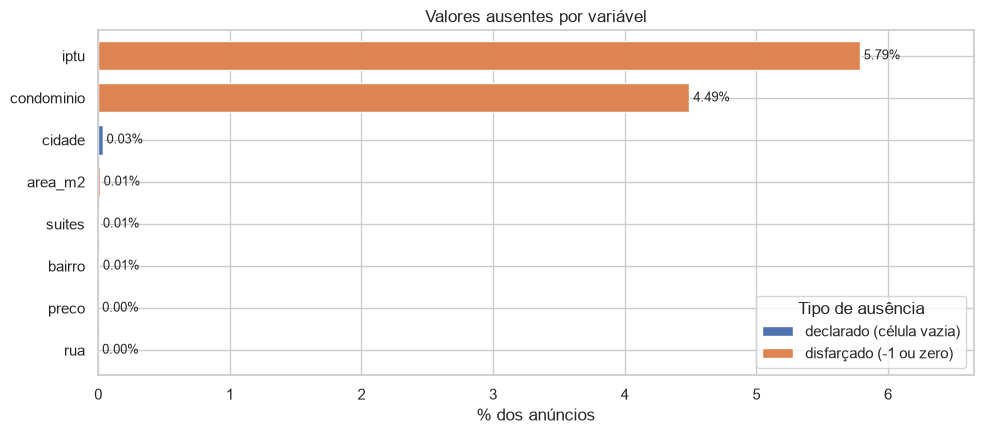

In [40]:
faltas = pd.DataFrame({
    "declarado (célula vazia)": df_raw[COLUNAS_ENUNCIADO + ["cidade", "suites"]].isna().sum(),
    "disfarçado (-1 ou zero)": pd.Series({
        CONDOMINIO: (nao_casa & df_raw[CONDOMINIO].eq(-1)).sum(),
        IPTU: df_raw[IPTU].eq(-1).sum(),
        AREA: df_raw[AREA].eq(0).sum(),
    }),
}).fillna(0) / len(df_raw) * 100
faltas = faltas.loc[faltas.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(10, 4.5))
faltas.plot.barh(stacked=True, ax=ax, color=["#4C72B0", "#DD8452"], width=0.7)
for i, total in enumerate(faltas.sum(axis=1)):
    ax.text(total, i, f" {total:.2f}%", va="center", fontsize=9)
ax.set(title="Valores ausentes por variável", xlabel="% dos anúncios", ylabel="")
ax.set_xlim(0, faltas.sum(axis=1).max() * 1.15)
ax.legend(title="Tipo de ausência", loc="lower right")
plt.tight_layout()
plt.show()

**Interpretação:** as duas variáveis com mais ausência, IPTU e condomínio, **não têm nenhuma célula vazia**: toda a ausência delas é disfarçada pelo código −1. Uma análise que olhasse apenas `isna()` concluiria, erradamente, que essas colunas estão completas. Nas demais variáveis, a ausência é pontual.

## 9.2 Boxplots do preço e da metragem

Cada boxplot é mostrado na escala original e na escala logarítmica. A metragem é desenhada só acima de zero.

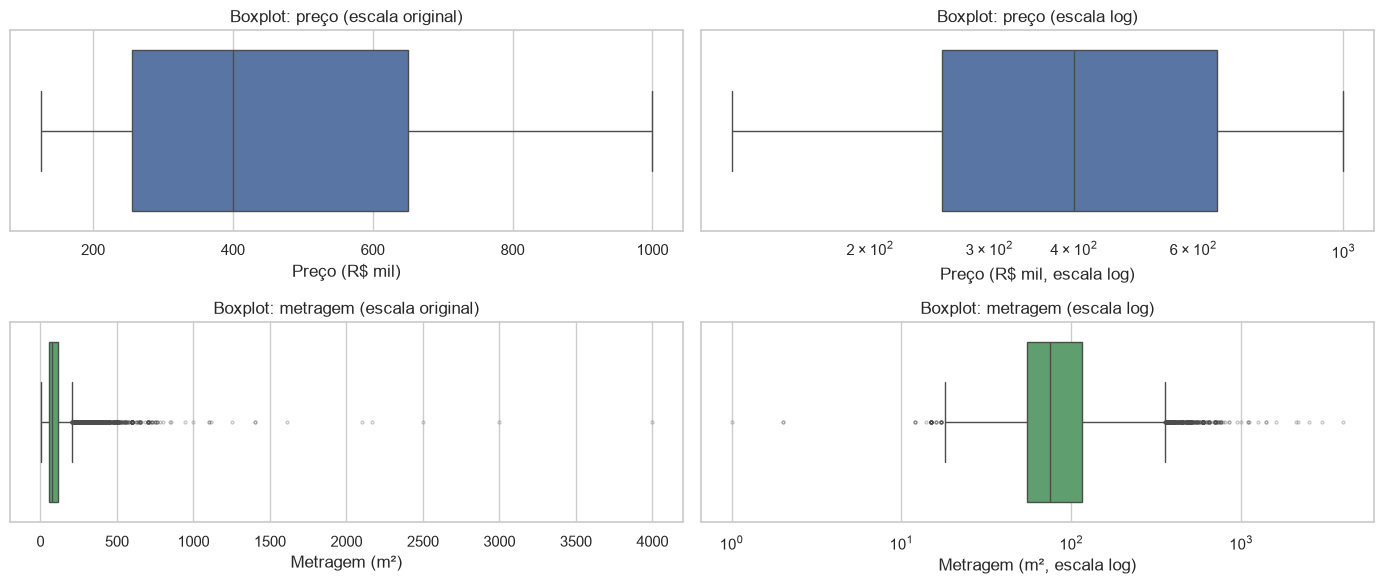

In [41]:
fig, eixos = plt.subplots(2, 2, figsize=(14, 6))

for linha, (coluna, nome, divisor, unidade, cor) in enumerate([
    (PRECO, "Preço", 1e3, "R$ mil", "#4C72B0"),
    (AREA, "Metragem", 1, "m²", "#55A868"),
]):
    valores = df_raw.loc[df_raw[coluna] > 0, coluna] / divisor
    sns.boxplot(x=valores, ax=eixos[linha, 0], color=cor, flierprops={"markersize": 2, "alpha": 0.3})
    eixos[linha, 0].set(title=f"Boxplot: {nome.lower()} (escala original)", xlabel=f"{nome} ({unidade})")
    sns.boxplot(x=valores, ax=eixos[linha, 1], color=cor, log_scale=True, flierprops={"markersize": 2, "alpha": 0.3})
    eixos[linha, 1].set(title=f"Boxplot: {nome.lower()} (escala log)", xlabel=f"{nome} ({unidade}, escala log)")

plt.tight_layout()
plt.show()

**Interpretação:**

- **Preço:** a caixa (os 50% centrais) vai de cerca de R$ 255 mil a R$ 650 mil, e os bigodes cobrem toda a faixa da coleta, de R$ 125 mil a R$ 1 milhão, **sem nenhum ponto isolado**. O teto da coleta eliminou os extremos. O boxplot também mostra uma limitação da técnica: o piso de R$ 200 mil, o maior problema do preço, **não aparece** nele. Ele só fica visível no histograma (seção 9.3).
- **Metragem:** na escala original, a caixa fica espremida à esquerda e centenas de pontos aparecem como *outliers*, até alguns milhares de m². Na escala log, a caixa fica centralizada, e os pontos isolados se reduzem às duas pontas: **à esquerda, as áreas de 1 a 9 m² (erros)**; à direita, as casas com terreno grande e os prováveis erros de cadastro.

## 9.3 Distribuições do preço e da metragem

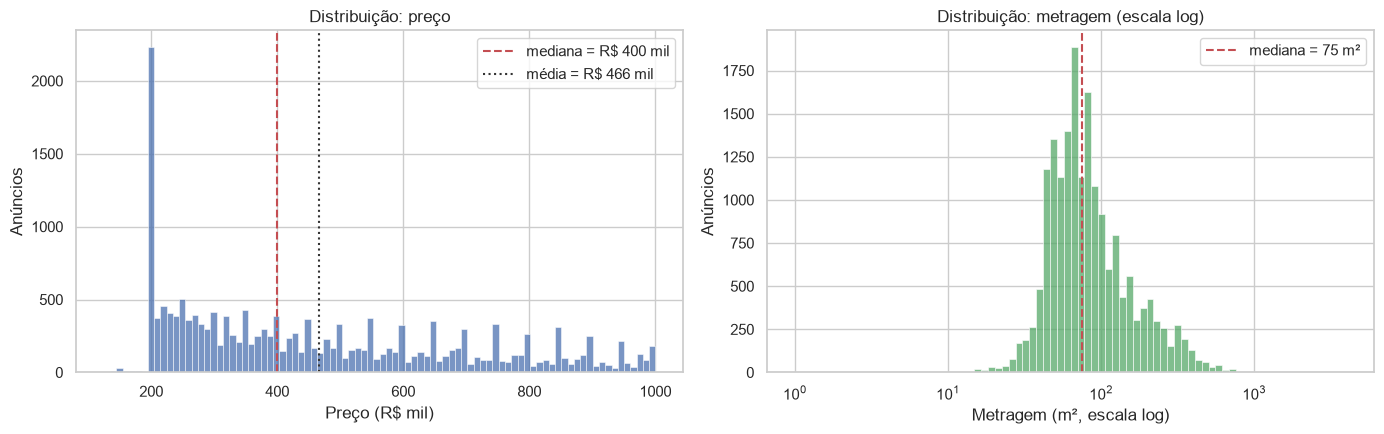

In [42]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.5))

precos = df_raw[PRECO] / 1e3
sns.histplot(precos, bins=88, ax=eixos[0], color="#4C72B0")
eixos[0].axvline(precos.median(), color="#C44E52", ls="--", label=f"mediana = R$ {precos.median():,.0f} mil")
eixos[0].axvline(precos.mean(), color="#333333", ls=":", label=f"média = R$ {precos.mean():,.0f} mil")
eixos[0].set(title="Distribuição: preço", xlabel="Preço (R$ mil)", ylabel="Anúncios")
eixos[0].legend()

areas = df_raw.loc[df_raw[AREA] > 0, AREA]
sns.histplot(areas, bins=80, ax=eixos[1], color="#55A868", log_scale=True)
eixos[1].axvline(areas.median(), color="#C44E52", ls="--", label=f"mediana = {areas.median():,.0f} m²")
eixos[1].set(title="Distribuição: metragem (escala log)", xlabel="Metragem (m², escala log)", ylabel="Anúncios")
eixos[1].legend()

plt.tight_layout()
plt.show()

**Interpretação:**

- **Preço:** a distribuição é assimétrica à direita (mais imóveis baratos que caros), com a média acima da mediana. O destaque é a **barra isolada em R$ 200 mil**, muito mais alta que todas as outras e com quase nada à esquerda: é o piso de preço da seção 5.6, o principal problema de qualidade visível neste gráfico. Também aparecem picos menores em valores "redondos" (R$ 250 mil, R$ 300 mil, R$ 350 mil...), um arredondamento natural dos preços anunciados. A distribuição termina abruptamente em R$ 1 milhão, o limite da coleta.
- **Metragem:** na escala log, a forma é próxima de um sino, concentrada entre 40 e 150 m². Os "dentes" do histograma mostram que muitos anunciantes **arredondam** a área (50, 60, 70, 80, 100 m²). Os poucos valores na extrema esquerda, abaixo de 10 m², são os erros de cadastro.

## 9.4 Complemento: condomínio e IPTU

As duas variáveis com mais problemas merecem um gráfico próprio. Usamos a escala log para enxergar ao mesmo tempo os valores normais e os absurdos:

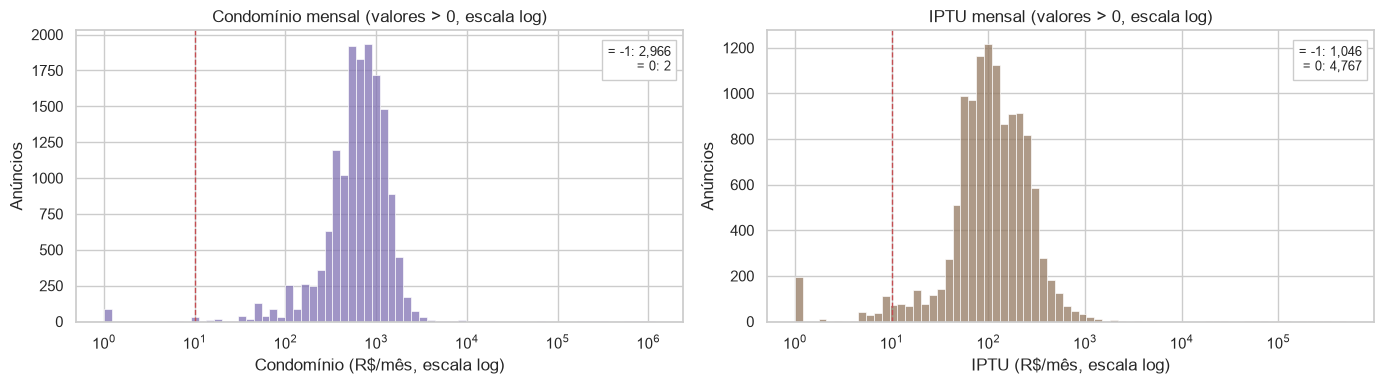

In [43]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
for ax, coluna, nome, cor in [(eixos[0], CONDOMINIO, "Condomínio", "#8172B3"), (eixos[1], IPTU, "IPTU", "#937860")]:
    positivos = df_raw.loc[df_raw[coluna] > 0, coluna]
    sns.histplot(positivos, bins=70, log_scale=True, ax=ax, color=cor)
    ax.axvline(10, color="#C44E52", ls="--", lw=1)
    ax.set(title=f"{nome} mensal (valores > 0, escala log)", xlabel=f"{nome} (R$/mês, escala log)", ylabel="Anúncios")
    ax.text(0.98, 0.95, f"= -1: {df_raw[coluna].eq(-1).sum():,}\n= 0: {df_raw[coluna].eq(0).sum():,}",
            transform=ax.transAxes, ha="right", va="top", fontsize=9,
            bbox={"facecolor": "white", "edgecolor": "#CCCCCC"})
plt.tight_layout()
plt.show()

**Interpretação:** o grosso dos condomínios fica entre algumas centenas e poucos milhares de reais, e o dos IPTUs entre dezenas e poucas centenas, faixas plausíveis para imóveis de até R$ 1 milhão. Mas os dois histogramas têm **caudas impossíveis à direita**, com valores de centenas de milhares de reais por mês, e grupos de valores simbólicos à esquerda da linha tracejada (R$ 10). Os quadros no canto lembram que, além do que aparece no gráfico, milhares de anúncios têm −1 ou zero, que não podem ser desenhados em escala log.

# 10. Diagnóstico final da qualidade dos dados

## Você considera essa base suficientemente confiável para realizar uma análise do mercado imobiliário do Rio de Janeiro?

**Sim, com ressalvas, e depois dos tratamentos propostos.** A base é confiável para analisar **preço e área por bairro** no segmento de **imóveis de até R$ 1 milhão anunciados diretamente pelo QuintoAndar**. Os custos de condomínio e IPTU podem ser usados com cuidado, depois de tratados. A base **não** representa o mercado inteiro: imóveis acima de R$ 1 milhão e anúncios de terceiros (classificados) ficaram de fora por construção da coleta, e o segmento mais barato está distorcido pelo piso de R$ 200 mil.

**Por que sim:**

- **Volume e cobertura:** mais de 18 mil anúncios, com 98,8% de cobertura do que a plataforma informa, distribuídos por cerca de 140 bairros (depois da padronização).
- **Variáveis centrais íntegras:** o preço está 100% preenchido, é sempre positivo e respeita o limite da coleta. Rua e bairro estão praticamente completos.
- **Formato correto:** todos os números chegaram como números, sem símbolos, graças à coleta pela API.
- **Sem anúncios repetidos** pelo código. As possíveis duplicatas de imóvel são poucas e estão sinalizadas.
- **Validação externa:** na etapa 1, os campos coincidiram com a base de referência do professor em quase 100% dos anúncios em comum.

## Principais problemas encontrados

| # | Problema | Variáveis | Seção |
|---|---|---|---|
| 1 | **Código −1** como "não informado" (ou "sem condomínio", nas casas de rua) | condomínio, IPTU | 2.2 |
| 2 | **Concentração de preços em exatamente R$ 200 mil** (provável piso da plataforma) | preço | 5.6 |
| 3 | **Grafias diferentes para o mesmo bairro**: espaços extras, maiúsculas/minúsculas, acentos, abreviações, complementos | bairro | 7.1 |
| 4 | **Campo de rua com formatos misturados**: só o nome, com número, endereço completo com CEP, abreviações | rua | 7.2 |
| 5 | Valores impossíveis: condomínio e IPTU de centenas de milhares de reais por mês, condomínios simbólicos | condomínio, IPTU | 5.3 e 5.4 |
| 6 | Metragem zero ou abaixo de 10 m², e áreas enormes com m² irrisório | metragem | 5.2 e 6.2 |
| 7 | Anúncios idênticos em todas as características com códigos diferentes | todas | 3.2 |
| 8 | IPTU zero ambíguo (isenção ou não informado) | IPTU | 2.2 |
| 9 | Cidade ausente ou preenchida com um bairro ("Lins") | cidade | 5.7 |

## Problemas corrigidos

- **Código −1:** nas casas de rua, convertido em 0 (sem condomínio); nos demais casos, transformado em ausente.
- **Valores impossíveis** de condomínio, IPTU e metragem: transformados em ausentes, preservando os anúncios.
- **Bairros:** espaços, caixa e acentos unificados pela forma mais frequente, e abreviações, erros e complementos corrigidos por dicionário.
- **Ruas:** reduzidas ao nome do logradouro, com espaços extras removidos e abreviações expandidas.
- **Cidade:** preenchida como Rio de Janeiro, confirmada pela rua e pelo bairro.
- **`condominio_iptu`** recalculado com os valores tratados, em vez da soma do site, que tratava −1 como zero.

## Problemas que permaneceram

- **O piso de R$ 200 mil** não pode ser corrigido sem o preço real. Os anúncios foram apenas sinalizados.
- **Possíveis duplicatas e áreas extremas** foram sinalizadas, não removidas. Sem o número do imóvel e o apartamento, não há como confirmar se são o mesmo imóvel.
- **Valores errados, mas plausíveis** (um condomínio de R$ 800 que deveria ser R$ 1.800) não são detectáveis.
- **IPTU zero:** não dá para distinguir isenção de falta de informação.
- **Variações de acento nas ruas** ("Americas" e "Américas"): sem uma lista oficial de logradouros, não há como saber com segurança qual é a forma correta.
- **Localidades não reconhecidas** e áreas arredondadas permanecem.

## Limitações provocadas pelo processo de *scraping*

1. **Cobertura parcial do mercado por decisão da coleta:** só anúncios próprios do QuintoAndar (os classificados são bloqueados pelo `robots.txt` e ficaram de fora) e só até R$ 1 milhão.
2. **Cobertura de 98,8%:** a API informa um total um pouco maior do que é possível recuperar pelas faixas de preço. A paginação instável da API, contornada na etapa 1, mostra que a fonte não é feita para coleta em massa.
3. **Dependência de uma API interna não documentada:** o formato pode mudar sem aviso e quebrar o *scraper*, e os códigos (como o −1) não têm documentação. O significado deles foi deduzido dos dados.
4. **Retrato de um único dia:** os preços mudam (na etapa 1, cerca de 10% dos anúncios mudaram de preço em 13 dias), e não há série histórica.
5. **Preço anunciado, não preço de venda:** o valor fechado costuma ser menor que o pedido.
6. **Dados digitados pelos anunciantes:** o *scraper* copia fielmente o que está no site, inclusive os erros de quem preencheu o cadastro. Os campos de texto livre (bairro e rua) concentram os problemas de padronização, e os campos opcionais (condomínio e IPTU) concentram os problemas de completude.

**Em resumo:** a coleta tem qualidade **alta nas variáveis centrais** (preço, localização) e **problemas sérios, porém tratáveis, nos custos** (condomínio e IPTU) e na **padronização dos textos** (bairro e rua). Com os tratamentos aplicados, ela é adequada para uma análise do mercado carioca de imóveis de até R$ 1 milhão no nível de bairro, desde que os resultados sejam apresentados com as ressalvas acima.